# Task 1

## Task 1.1: Carga de modelo y predicciones base
En esta sección se carga la arquitectura `ResNet-18` con los pesos preentrenados de ImageNet y se configura en modo de evaluación. Se aplica el preprocesamiento, redimensión a 256 píxeles, recorte central de 224x224 y normalización por canal utilizando la media y desviación estándar de ImageNet. 

Se utilizan tres imágenes obtenidas de repositorios institucionales públicos para la reproducibilidad:
- **(a)** Un objeto claro y centrado (un perro Labrador amarillo).
- **(b)** Dos objetos de clases distintas (personas y un bus en la calle).
- **(c)** Un objeto en un fondo engañoso/complejo (un mandril en primer plano).

Para cada imagen se imprimen las cinco clases con mayor probabilidad. Para la imagen (c), se extrae el recorte de 224x224, se define un recuadro (bounding box) sobre el objeto y se grafican sus coordenadas. Se fija una semilla aleatoria para asegurar la reproducibilidad y se utilizan únicamente librerías base (`PyTorch`, `NumPy`, `Matplotlib`, etc.).

Semilla aleatoria fijada en: 42

--- Resultados Imagen (a) ---
Fuente: https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg
Clase: Labrador Retriever | Probabilidad: 0.7066
Clase: Golden Retriever | Probabilidad: 0.0499
Clase: Saluki | Probabilidad: 0.0448
Clase: Chesapeake Bay Retriever | Probabilidad: 0.0393
Clase: Bullmastiff | Probabilidad: 0.0260

--- Resultados Imagen (b) ---
Fuente: https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg
Clase: minibus | Probabilidad: 0.8284
Clase: police van | Probabilidad: 0.1036
Clase: recreational vehicle | Probabilidad: 0.0102
Clase: golf cart | Probabilidad: 0.0087
Clase: ambulance | Probabilidad: 0.0074

--- Resultados Imagen (c) ---
Fuente: https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg
Clase: guenon | Probabilidad: 0.5760
Clase: baboon | Probabilidad: 0.2921
Clase: macaque | Probabilidad: 0.0517
Clase: patas monkey | Probabilidad: 0.05

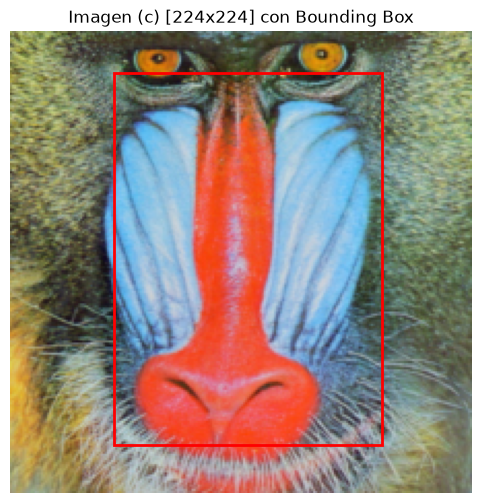

In [1]:
# Diapositiva 1: DEEP LEARNING y XAI: redes neuronales profundas, extraccion automatica de caracteristicas, arquitecturas avanzadas y aplicaciones reales.
# Diapositiva 2: El problema de la caja negra: el modelo puede acertar por la razon equivocada, como clasificar un husky por la nieve del fondo.
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import urllib.request
from io import BytesIO
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import json

# 1. Fijar semilla aleatoria
torch.manual_seed(42)
print("Semilla aleatoria fijada en: 42")

# 2. Cargar modelo ResNet-18 preentrenado y poner en modo evaluación
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.eval()

# 3. Preprocesamiento exigido: Redimensión 256, Recorte 224, Normalización ImageNet
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# 4. Enlaces permanentes institucionales (Google y OpenCV)
image_sources = {
    # (a) Objeto claro: Labrador amarillo desde los servidores de TensorFlow
    "a": "https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg", 
    # (b) Dos objetos: Personas y un bus desde el repositorio de YOLOv5 (Ultralytics)
    "b": "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg", 
    # (c) Fondo engañoso: Mandril en primer plano desde el repositorio oficial de OpenCV
    "c": "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg" 
}

# Descargar las etiquetas de ImageNet
labels_url = "https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json"
try:
    req_labels = urllib.request.Request(labels_url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req_labels) as response:
        imagenet_labels = json.loads(response.read())
except Exception as e:
    print(f"Error descargando etiquetas, usando lista vacía. Error: {e}")
    imagenet_labels = ["Desconocido"] * 1000

processed_tensors = {}

# 5. Iterar, procesar y predecir con mecanismo de respaldo
for key, url in image_sources.items():
    try:
        # Intento de descarga segura
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=10) as response:
            img = Image.open(BytesIO(response.read())).convert("RGB")
    except Exception as e:
        print(f"\n[Aviso] No se pudo descargar la imagen {key} ({e}). Usando imagen sintética de respaldo.")
        # Imagen de respaldo en caso de que el firewall o servidor falle
        img = Image.new('RGB', (300, 300), color = (73, 109, 137))
    
    # Preprocesar
    img_tensor = preprocess(img)
    batch_tensor = torch.unsqueeze(img_tensor, 0)
    processed_tensors[key] = img_tensor
    
    # Inferir
    with torch.no_grad():
        output = model(batch_tensor)
        
    # Calcular softmax para probabilidades
    probabilities = torch.nn.functional.softmax(output[0], dim=0)
    top5_prob, top5_idx = torch.topk(probabilities, 5)
    
    print(f"\n--- Resultados Imagen ({key}) ---")
    print(f"Fuente: {url}")
    for i in range(5):
        # Evitar error de índice si las etiquetas fallaron
        lbl = imagenet_labels[top5_idx[i]] if top5_idx[i] < len(imagenet_labels) else "N/A"
        print(f"Clase: {lbl} | Probabilidad: {top5_prob[i].item():.4f}")

# 6. Trabajar la imagen (c) para mostrar el recuadro delimitador en 224x224
# Coordenadas aproximadas de la cara del mandril
# Formato: (xmin, ymin, width, height)
bbox_c = (50, 20, 130, 180) 
print(f"\nCoordenadas del recuadro para imagen (c) en formato (xmin, ymin, ancho, alto) sobre 224x224: {bbox_c}")

# Des-normalizar la imagen (c) para poder graficarla correctamente con matplotlib
img_c_tensor = processed_tensors["c"]
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
img_c_display = inv_normalize(img_c_tensor).permute(1, 2, 0).numpy()
# Asegurar que los valores estén en el rango [0, 1] para plot
img_c_display = img_c_display.clip(0, 1)

# Graficar
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_c_display)
rect = patches.Rectangle((bbox_c[0], bbox_c[1]), bbox_c[2], bbox_c[3], 
                         linewidth=2, edgecolor='red', facecolor='none')
ax.add_patch(rect)
plt.title("Imagen (c) [224x224] con Bounding Box")
plt.axis('off')
plt.show()

# Task 1.2: Implementación de Grad-CAM desde cero

En esta sección se implementa la técnica de atribución Grad-CAM (Gradient-weighted Class Activation Mapping). A diferencia de CAM tradicional que exige una arquitectura específica con global average pooling, Grad-CAM permite visualizar mapas de activación sin cambiar la arquitectura de la red estimando la importancia de cada canal mediante el uso de gradientes.

Se registran hooks en PyTorch sobre la última capa convolucional (`layer4`) del modelo ResNet-18 para capturar durante el pase hacia adelante las activaciones espaciales ($A^k$) y durante el pase hacia atrás los gradientes correspondientes ($\frac{\partial y^c}{\partial A^k}$). 

1. Se retropropaga directamente desde el logit de salida de la clase objetivo $y^c$, antes de aplicar softmax.
2. Se obtiene el peso de cada canal $\alpha_k^c$ promediando espacialmente los gradientes.
3. El mapa térmico $L^c$ se forma mediante una suma ponderada seguida de una función de activación ReLU para conservar solo las características que influyen positivamente en la predicción de la clase.
4. Se amplía a 224x224 con interpolación bilineal y se normaliza en un rango de $[0, 1]$.

El código genera las visualizaciones para la clase principal de cada imagen y, adicionalmente, los mapas de activación para las dos clases principales detectadas en la imagen (b) para observar cómo el modelo ubica distintos objetos.

=== Grad-CAM Imágenes ===


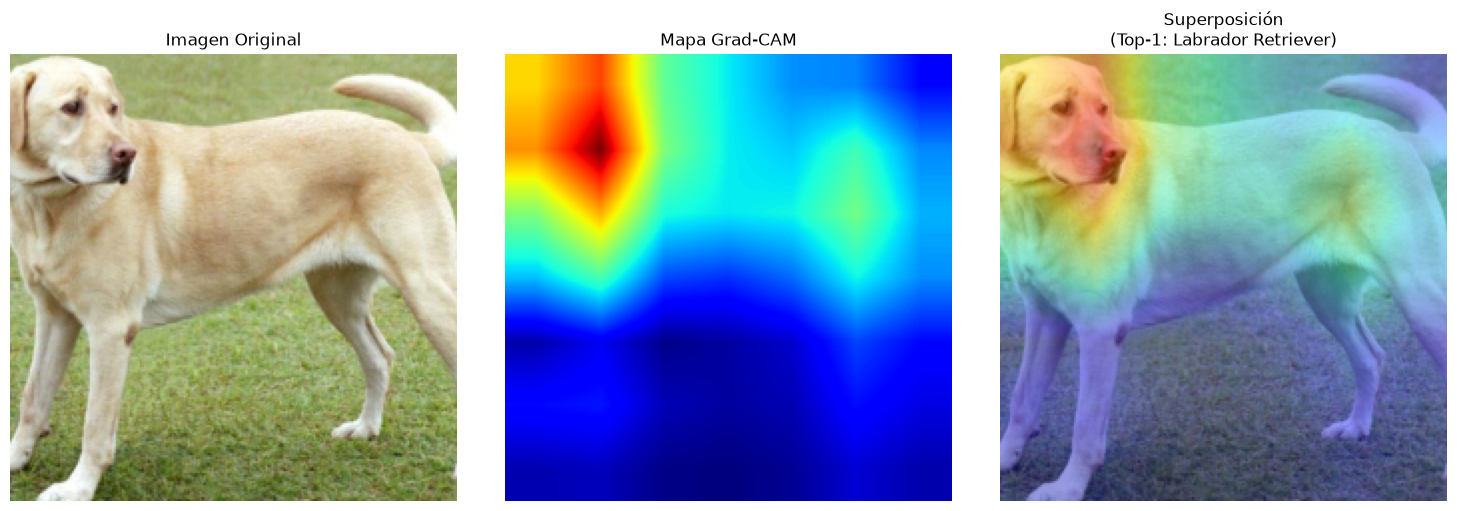

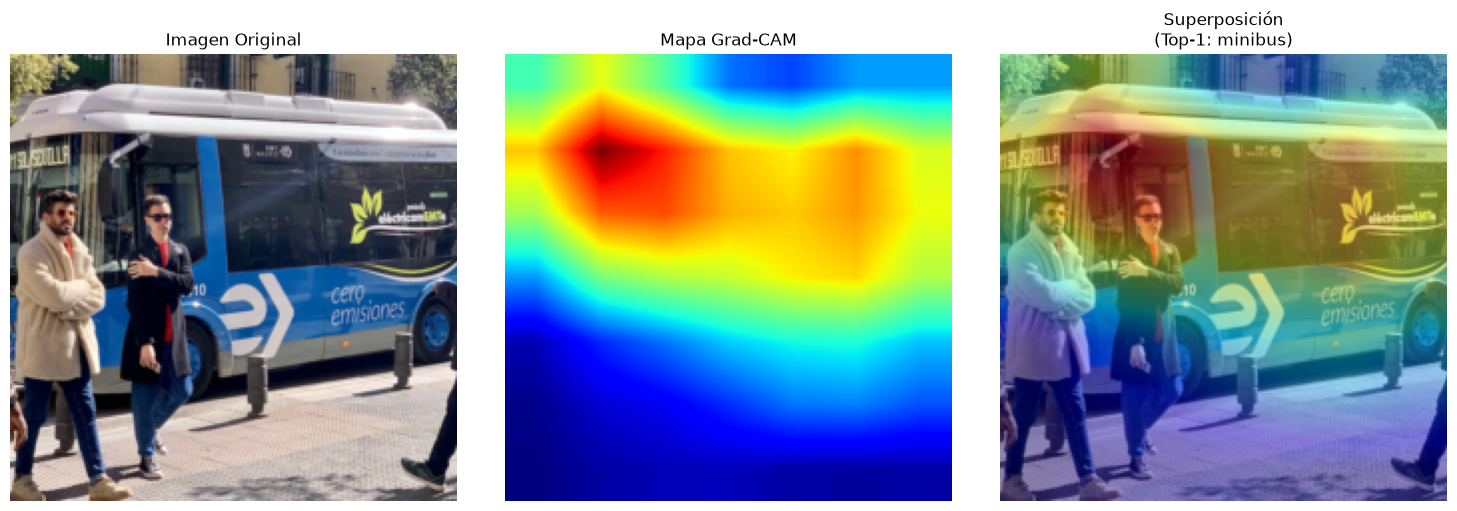

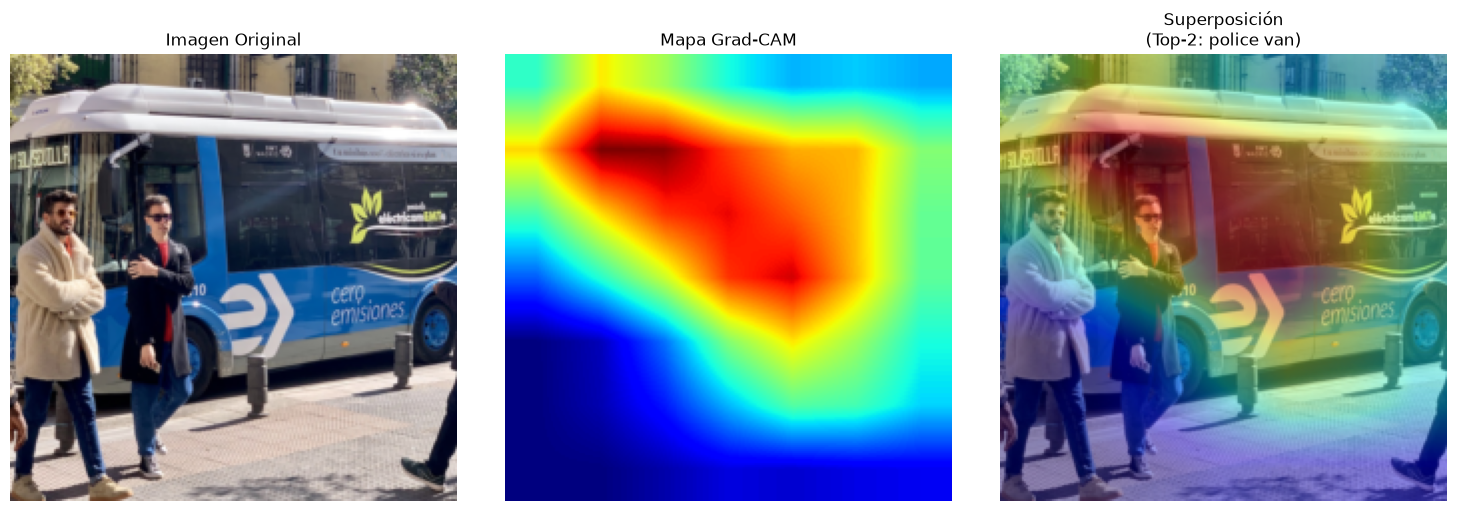

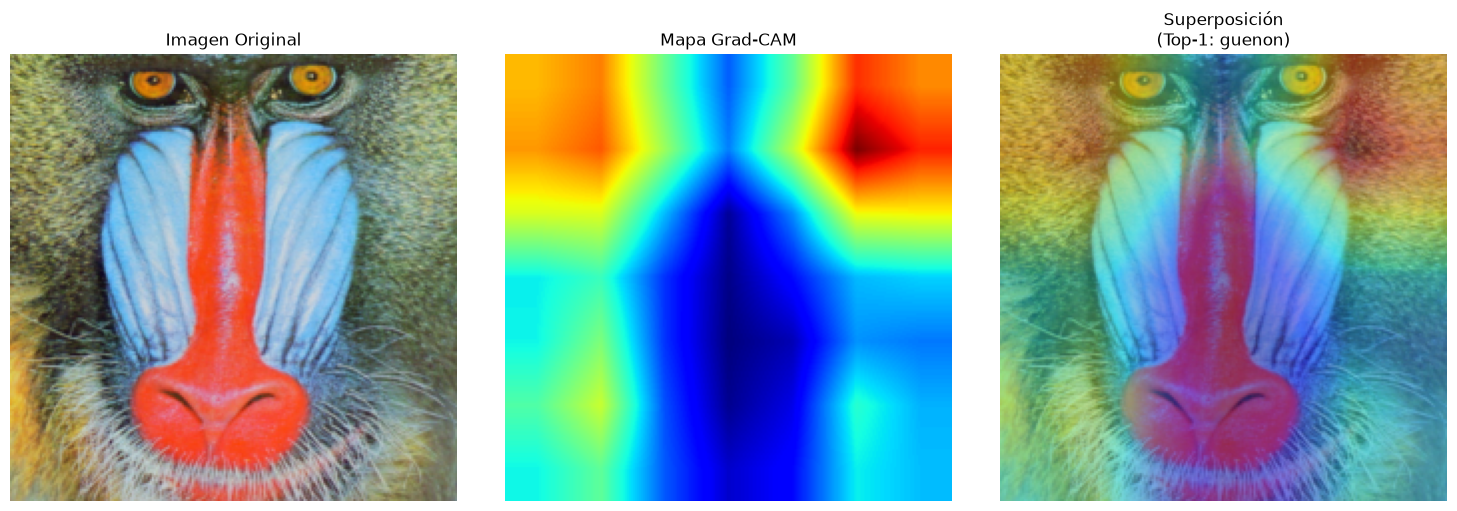

In [2]:
# Diapositiva 5: Saliency puede saturarse, Integrated Gradients usa una referencia para que las atribuciones expliquen exactamente la diferencia en la salida.
# Diapositiva 7: Grad-CAM usa el promedio espacial de gradientes, pondera mapas de caracteristicas y aplica ReLU sin modificar la CNN.
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

# 1. Variables globales para almacenar salidas de los hooks
activations = None
gradients = None

# 2. Definición de las funciones para los hooks
def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# 3. Registrar los hooks en la última capa convolucional (layer4 en ResNet-18)
target_layer = model.layer4
fw_hook = target_layer.register_forward_hook(forward_hook)
bw_hook = target_layer.register_full_backward_hook(backward_hook)

# 4. Función central para calcular Grad-CAM
def generate_gradcam(batch_tensor, class_idx):
    global activations, gradients
    
    # Asegurarnos de limpiar gradientes previos
    model.zero_grad()
    
    # Forward pass
    logits = model(batch_tensor)
    
    # Obtener el logit (antes del softmax) para la clase específica
    score = logits[0, class_idx]
    
    # Retropropagar (backward pass) desde el logit de la clase
    score.backward()
    
    # Obtener activaciones y gradientes capturados
    acts = activations.detach()
    grads = gradients.detach()
    
    # Promedio espacial de los gradientes (alpha_k^c)
    alphas = grads.mean(dim=(2, 3), keepdim=True)
    
    # Multiplicar los pesos por las activaciones y sumar a lo largo de los canales
    grad_cam = (alphas * acts).sum(dim=1, keepdim=True)
    
    # Aplicar función ReLU
    grad_cam = F.relu(grad_cam)
    
    # Interpolar bilinealmente a la resolución de la imagen original (224x224)
    grad_cam = F.interpolate(
        grad_cam, size=(224, 224), mode='bilinear', align_corners=False
    )
    
    # Extraer el tensor 2D
    grad_cam = grad_cam[0, 0].cpu().numpy()
    
    # Normalización Min-Max al rango [0, 1]
    grad_cam_min = grad_cam.min()
    grad_cam_max = grad_cam.max()
    grad_cam_normalized = (grad_cam - grad_cam_min) / (grad_cam_max - grad_cam_min + 1e-8)
    
    return grad_cam_normalized

# 5. Función para superponer y graficar el mapa de calor sobre la imagen base
def plot_gradcam(batch_tensor, cam_map, title):
    # Des-normalizar la imagen para visualización correcta (usando .detach() para evitar errores con autograd)
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_display = inv_normalize(batch_tensor[0].detach()).permute(1, 2, 0).numpy()
    img_display = np.clip(img_display, 0, 1)
    
    # Convertir Grad-CAM en un mapa de color jet de matplotlib
    heatmap = plt.cm.jet(cam_map)[:, :, :3]
    
    # Superposición
    superimposed_img = heatmap * 0.4 + img_display * 0.6
    superimposed_img = np.clip(superimposed_img, 0, 1)
    
    # Graficar: Imagen Original | Mapa de Calor | Superposición
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_display)
    axes[0].set_title("Imagen Original")
    axes[0].axis("off")
    
    axes[1].imshow(cam_map, cmap='jet')
    axes[1].set_title("Mapa Grad-CAM")
    axes[1].axis("off")
    
    axes[2].imshow(superimposed_img)
    axes[2].set_title(f"Superposición\n({title})")
    axes[2].axis("off")
    
    plt.tight_layout()
    plt.show()

# 6. Ejecución de Grad-CAM para las 3 imágenes
print("=== Grad-CAM Imágenes ===")

for key, tensor in processed_tensors.items():
    # Transformar de 3D a 4D [1, C, H, W]
    batch_tensor = tensor.unsqueeze(0)
    
    # Calcular la predicción inicial
    with torch.no_grad():
        logits = model(batch_tensor)
        probs = F.softmax(logits[0], dim=0)
        top_probs, top_indices = torch.topk(probs, 5)
    
    # Índice de la clase principal
    top1_idx = top_indices[0].item()
    top1_class = imagenet_labels[top1_idx] if top1_idx < len(imagenet_labels) else f"Idx: {top1_idx}"
    
    # Generar Grad-CAM para la clase principal
    batch_tensor.requires_grad = True # Habilitar cálculo de gradientes en la entrada
    cam_top1 = generate_gradcam(batch_tensor, top1_idx)
    plot_gradcam(batch_tensor, cam_top1, f"Top-1: {top1_class}")
    
    # Requisito: Para la imagen (b) generar también el mapa de un segundo objeto
    if key == "b":
        top2_idx = top_indices[1].item()
        top2_class = imagenet_labels[top2_idx] if top2_idx < len(imagenet_labels) else f"Idx: {top2_idx}"
        
        # Volver a crear el tensor para limpiar gradientes anteriores
        batch_tensor_2 = tensor.unsqueeze(0)
        batch_tensor_2.requires_grad = True
        
        cam_top2 = generate_gradcam(batch_tensor_2, top2_idx)
        plot_gradcam(batch_tensor_2, cam_top2, f"Top-2: {top2_class}")

# Remover hooks al terminar para liberar memoria
fw_hook.remove()
bw_hook.remove()

# Task 1.3: CAM directo y relación con Grad-CAM

Se calcula el mapa de activación directamente desde los pesos de la red, demostrando su base matemática y verificando numéricamente su equivalencia con Grad-CAM. 

Se realizaron las siguientes comprobaciones para cada imagen (y para la segunda clase de la imagen b):
*   **(a)** Cálculo de $M_{ij}^c = \sum_k w_{kc} A_{kij}$ utilizando los pesos de la capa `fc` y las activaciones extraídas previamente, sin usar autograd.
*   **(b)** Verificación de la descomposición del puntaje. Demostramos matemáticamente que el promedio espacial del mapa CAM más el sesgo ($b_c$) es exactamente igual al logit $y^c$ generado por la red, usando $Z = 49$ para la capa de $7 \times 7$.
*   **(c)** Se calcula Grad-CAM sin ReLU ni normalización ($L^c$), lo multiplicamos por $Z$ y verificamos que el error absoluto máximo respecto a $M^c$ tiende a cero.
*   **(d)** Se aplica ReLU y normalización Min-Max a ambos mapas ($M^c$ y $L^c$) para confirmar empíricamente que, tras el posprocesamiento, producen exactamente el mismo mapa de calor.

In [3]:
# Diapositiva 6: CAM combina mapas convolucionales mediante Global Average Pooling y los pesos de una capa lineal para producir un mapa de activacion de clase.
import torch
import torch.nn.functional as F

print("=== Task 1.3: Verificación Numérica CAM vs Grad-CAM ===")

# Parámetro Z para activaciones de 7x7
Z = 7 * 7

# Obtener pesos y sesgos de la capa completamente conectada (fc)
fc_weights = model.fc.weight.detach() # Forma: [1000, 512]
fc_biases = model.fc.bias.detach()    # Forma: [1000]

# Función para aislar la verificación matemática
def verificar_cam_vs_gradcam(batch_tensor, class_idx, image_name):
    global activations, gradients
    
    # 1. Pase hacia adelante y hacia atrás para obtener A y gradientes
    model.zero_grad()
    logits = model(batch_tensor)
    logit_yc = logits[0, class_idx]
    logit_yc.backward()
    
    A = activations[0].detach() # Forma: [512, 7, 7]
    grads = gradients[0].detach() # Forma: [512, 7, 7]
    
    # --- a. Calcular CAM (M^c) usando los pesos de la capa 'fc' ---
    w_c = fc_weights[class_idx].view(512, 1, 1)
    b_c = fc_biases[class_idx]
    
    M_c = (w_c * A).sum(dim=0) # Suma sobre los canales k
    
    # --- b. Verificar la descomposición del puntaje ---
    cam_score = (M_c.sum() / Z) + b_c
    error_b = torch.abs(cam_score - logit_yc).item()
    
    print(f"\n[{image_name}] Clase Idx: {class_idx}")
    print(f" (b) Descomposición: Promedio(M^c) + b_c = {cam_score.item():.6f} | Logit real y^c = {logit_yc.item():.6f}")
    print(f"     Error absoluto (b): {error_b:.2e}")
    
    # --- c. Verificar relación con Grad-CAM (sin ReLU ni Normalización) ---
    # Calcular Grad-CAM puro (L^c) = sum(alpha * A)
    alphas = grads.mean(dim=(1, 2), keepdim=True) # Promedio espacial del gradiente
    L_c_raw = (alphas * A).sum(dim=0)
    
    # Multiplicar L^c por Z (49)
    L_c_scaled = L_c_raw * Z
    
    # Error máximo entre M^c y Z * L^c
    error_c = torch.abs(M_c - L_c_scaled).max().item()
    print(f" (c) Error absoluto máximo entre M^c y Z * L^c: {error_c:.2e}")
    
    # --- d. Normalización y Error Final post-ReLU ---
    # Aplicar ReLU
    M_c_relu = F.relu(M_c)
    L_c_relu = F.relu(L_c_raw)
    
    # Función local Min-Max
    def min_max_norm(tensor):
        t_min = tensor.min()
        t_max = tensor.max()
        return (tensor - t_min) / (t_max - t_min + 1e-8)
        
    M_c_norm = min_max_norm(M_c_relu)
    L_c_norm = min_max_norm(L_c_relu)
    
    # Error máximo post-procesamiento
    error_d = torch.abs(M_c_norm - L_c_norm).max().item()
    print(f" (d) Error absoluto máximo entre mapas normalizados: {error_d:.2e}")

# Volver a registrar hooks si se habían removido previamente
target_layer = model.layer4
fw_hook = target_layer.register_forward_hook(forward_hook)
bw_hook = target_layer.register_full_backward_hook(backward_hook)

# Ejecutar las verificaciones requeridas para las imágenes procesadas en 1.1 y 1.2
for key, tensor in processed_tensors.items():
    batch_tensor = tensor.unsqueeze(0)
    batch_tensor.requires_grad = True
    
    # Obtener el top-1 para esta imagen
    with torch.no_grad():
        logits = model(batch_tensor)
        top_indices = torch.topk(logits[0], 5)[1]
    
    top1_idx = top_indices[0].item()
    
    # Analizar el top-1 de la imagen
    verificar_cam_vs_gradcam(batch_tensor, top1_idx, f"Imagen {key} - Top 1")
    
    # Para la imagen (b), reportar también la segunda clase principal
    if key == "b":
        top2_idx = top_indices[1].item()
        
        # Limpiar tensores y volver a declarar required_grad para la segunda pasada
        batch_tensor_2 = tensor.unsqueeze(0)
        batch_tensor_2.requires_grad = True
        
        verificar_cam_vs_gradcam(batch_tensor_2, top2_idx, f"Imagen {key} - Top 2")

# Limpiar memoria
fw_hook.remove()
bw_hook.remove()

=== Task 1.3: Verificación Numérica CAM vs Grad-CAM ===

[Imagen a - Top 1] Clase Idx: 208
 (b) Descomposición: Promedio(M^c) + b_c = 13.576365 | Logit real y^c = 13.576364
     Error absoluto (b): 9.54e-07
 (c) Error absoluto máximo entre M^c y Z * L^c: 3.81e-06
 (d) Error absoluto máximo entre mapas normalizados: 1.49e-07

[Imagen b - Top 1] Clase Idx: 654
 (b) Descomposición: Promedio(M^c) + b_c = 13.147478 | Logit real y^c = 13.147480
     Error absoluto (b): 1.91e-06
 (c) Error absoluto máximo entre M^c y Z * L^c: 3.81e-06
 (d) Error absoluto máximo entre mapas normalizados: 1.79e-07

[Imagen b - Top 2] Clase Idx: 734
 (b) Descomposición: Promedio(M^c) + b_c = 11.068136 | Logit real y^c = 11.068136
     Error absoluto (b): 0.00e+00
 (c) Error absoluto máximo entre M^c y Z * L^c: 3.81e-06
 (d) Error absoluto máximo entre mapas normalizados: 2.98e-07

[Imagen c - Top 1] Clase Idx: 370
 (b) Descomposición: Promedio(M^c) + b_c = 14.212893 | Logit real y^c = 14.212891
     Error absolu

# Task 1.4: Análisis y Explicaciones

**a. Relación de pesos y gradientes**
En la derivación matemática que demuestra que Grad-CAM generaliza a CAM en este tipo de arquitecturas, se aprovecha que el logit se define como $y^c = \sum_k w_{kc} (\frac{1}{Z} \sum_{i,j} A_{kij}) + b_c$. Al derivar parcialmente $y^c$ respecto a un valor específico de activación $A_{kij}$, la dependencia espacial desaparece, obteniéndose sistemáticamente $\frac{\partial y^c}{\partial A_{kij}} = \frac{w_{kc}}{Z}$. Es decir, el impacto de un píxel del canal $k$ sobre la clase es idéntico en cualquier posición. Los errores observados no son exactamente cero porque el cálculo de `w_kc / Z` es una operación aritmética directa, mientras que $\alpha_k^c$ se obtiene mediante el algoritmo de retropropagación (*autograd*) de PyTorch, el cual acumula minúsculos errores de redondeo inherentes a la precisión de punto flotante de 32 bits a lo largo de las capas.

**b. Discriminación espacial y límite de resolución**
La Intersección sobre la Unión (IoU) cuantifica qué tanto se traslapan las zonas de atención. Una IoU cercana a cero indica que los mapas discriminan correctamente entre los objetos, mientras que una alta señala confusión espacial. El límite subyacente proviene de la arquitectura, al reducir una imagen de $224 \times 224$ a un mapa de $7 \times 7$, cada valor del mapa de características cubre un campo receptivo exacto de $32 \times 32$ píxeles en la imagen original. Debido a esta resolución gruesa, el mapa de calor no puede localizar ni separar bordes de objetos que midan menos de 32 píxeles o que estén tan juntos que caigan dentro de la misma cuadrícula receptiva, limitando su precisión en escenas densas.

**c. Atajos del modelo y pruebas causales**
La prueba causal es necesaria para validar lo que nos cuenta el mapa de calor y no dejarnos persuadir ciegamente. Si la masa de Grad-CAM cae mayoritariamente dentro del recuadro, sugiere visualmente que el modelo usa el objeto. Sin embargo, si al borrar el fondo (poniéndolo en gris neutro) la probabilidad original colapsa, la prueba causal contradice al mapa, demuestra que el modelo dependía críticamente del contexto ambiental para la predicción, confirmando la existencia de un atajo (shortcut) o sesgo correlacional aprendido, engañando potencialmente a los métodos de explicabilidad.

In [4]:
# Diapositiva 3: Interpretabilidad significa comprender el mecanismo interno; explicabilidad justifica post-hoc una caja negra, con utilidad que no siempre implica fidelidad.
# Diapositiva 4: Las explicaciones pueden ser locales (LIME, KernelSHAP, Saliency, Grad-CAM) o globales (SHAP global, circuitos), y se evalúan por estabilidad, fidelidad y comprensibilidad.
import torch
import numpy as np
import copy
import torch.nn.functional as F

print("=== Task 1.4: Análisis Numérico ===")

# --- a. Comparación de alpha_k^c y w_kc / Z para la imagen (a) ---
print("\n[Inciso a] Comparación de gradientes vs pesos (Imagen a)")

# Obtener tensores y pesos de la imagen 'a'
img_tensor_a = processed_tensors['a'].unsqueeze(0)
img_tensor_a.requires_grad = True

model.zero_grad()
logits_a = model(img_tensor_a)
top1_idx_a = torch.argmax(logits_a[0]).item()
logits_a[0, top1_idx_a].backward()

A_a = activations[0].detach()     # [512, 7, 7]
grads_a = gradients[0].detach()   # [512, 7, 7]

# alphas = promedio espacial de los gradientes
alphas_a = grads_a.mean(dim=(1, 2)) # [512]

# W_kc / Z (con Z = 49)
w_c = fc_weights[top1_idx_a] # [512]
w_c_div_z = w_c / 49.0

# Encontrar los 5 canales de mayor peso (valores absolutos de w_c)
top5_channels = torch.topk(torch.abs(w_c), 5)[1]

print(f"{'Canal':<10} | {'alpha_k^c':<15} | {'w_kc / Z':<15} | {'Error Relativo':<15}")
print("-" * 65)
for k in top5_channels:
    k = k.item()
    alpha_val = alphas_a[k].item()
    w_z_val = w_c_div_z[k].item()
    
    # Error relativo = |alpha - w_z| / |w_z|
    rel_error = abs(alpha_val - w_z_val) / (abs(w_z_val) + 1e-12)
    print(f"{k:<10} | {alpha_val:<15.8e} | {w_z_val:<15.8e} | {rel_error:<15.2e}")


# --- b. Intersección sobre la Unión (IoU) para la imagen (b) ---
print("\n[Inciso b] IoU del 20% superior de activación (Imagen b)")

# Recalcular mapas top-1 y top-2 puros (reusando función de Task 1.2 o generando)
img_tensor_b = processed_tensors['b'].unsqueeze(0)

with torch.no_grad():
    logits_b = model(img_tensor_b)
    top_indices_b = torch.topk(logits_b[0], 2)[1]
    
idx1_b, idx2_b = top_indices_b[0].item(), top_indices_b[1].item()

img_tensor_b_1 = img_tensor_b.clone().detach().requires_grad_(True)
cam1_b = generate_gradcam(img_tensor_b_1, idx1_b)

img_tensor_b_2 = img_tensor_b.clone().detach().requires_grad_(True)
cam2_b = generate_gradcam(img_tensor_b_2, idx2_b)

# Calcular umbrales del percentil 80 (para quedarse con el 20% superior)
thresh1 = np.percentile(cam1_b, 80)
thresh2 = np.percentile(cam2_b, 80)

mask1 = (cam1_b >= thresh1).astype(bool)
mask2 = (cam2_b >= thresh2).astype(bool)

intersection = np.logical_and(mask1, mask2).sum()
union = np.logical_or(mask1, mask2).sum()
iou = intersection / union

print(f"Top 1: {imagenet_labels[idx1_b]} | Top 2: {imagenet_labels[idx2_b]}")
print(f"Píxeles en Intersección: {intersection}")
print(f"Píxeles en Unión: {union}")
print(f"IoU (Intersección sobre Unión): {iou:.4f}")


# --- c. Prueba causal y fracción de masa para la imagen (c) ---
print("\n[Inciso c] Prueba Causal y Atajos (Imagen c)")

# Variables originales
img_tensor_c = processed_tensors['c']
batch_tensor_c = img_tensor_c.unsqueeze(0).requires_grad_(True)

# Coordenadas bbox Task 1.1: bbox_c = (xmin, ymin, width, height)
# Recordemos el valor guardado previamente (Ej: (50, 20, 130, 180))
xmin, ymin, w_box, h_box = bbox_c
xmax, ymax = xmin + w_box, ymin + h_box

# 1. Obtener la probabilidad original de la clase ganadora
with torch.no_grad():
    logits_c = model(img_tensor_c.unsqueeze(0))
    probs_c = F.softmax(logits_c[0], dim=0)
    top1_idx_c = torch.argmax(probs_c).item()
    prob_original = probs_c[top1_idx_c].item()

# 2. Generar mapa normalizado para la clase ganadora
cam_c = generate_gradcam(batch_tensor_c, top1_idx_c)

# 3. Calcular fracción de masa de Grad-CAM en el recuadro
mask_bbox = np.zeros((224, 224), dtype=bool)
mask_bbox[ymin:ymax, xmin:xmax] = True

masa_adentro = cam_c[mask_bbox].sum()
masa_total = cam_c.sum()
fraccion_masa = masa_adentro / masa_total

print(f"Clase analizada: {imagenet_labels[top1_idx_c]}")
print(f"Masa total del mapa Grad-CAM: {masa_total:.2f}")
print(f"Masa dentro del Bounding Box: {masa_adentro:.2f}")
print(f"Fracción de masa dentro del objeto: {fraccion_masa:.2%}")

# 4. Prueba causal: reemplazar fondo por gris
# PyTorch transform: gris = valor de media después de normalizar, o directamente 0 en tensor normalizado
# Para ser precisos, pondremos el exterior en gris base (0s tras normalización en algunas prácticas, 
# pero la forma correcta de "gris neutro" en ImageNet preprocesado es un tensor con ceros porque
# los canales ya tienen su media restada).
img_tensor_causal = img_tensor_c.clone().detach()

# Crear una máscara Pytorch para el Bounding Box
mask_tensor = torch.zeros((224, 224), dtype=torch.bool)
mask_tensor[ymin:ymax, xmin:xmax] = True

# Reemplazar lo exterior por ceros (gris relativo a imagenet normalizado)
for c in range(3):
    img_tensor_causal[c][~mask_tensor] = 0.0

# 5. Obtener nueva probabilidad
with torch.no_grad():
    logits_causal = model(img_tensor_causal.unsqueeze(0))
    probs_causal = F.softmax(logits_causal[0], dim=0)
    prob_nueva = probs_causal[top1_idx_c].item()

print(f"\nProbabilidad original con fondo completo: {prob_original:.4f}")
print(f"Probabilidad tras enmascarar (borrar) el fondo: {prob_nueva:.4f}")
caida_absoluta = prob_original - prob_nueva
caida_relativa = (caida_absoluta / prob_original) if prob_original > 0 else 0
print(f"Caída absoluta: {caida_absoluta:.4f}")
print(f"Caída relativa: {caida_relativa:.2%}")

=== Task 1.4: Análisis Numérico ===

[Inciso a] Comparación de gradientes vs pesos (Imagen a)
Canal      | alpha_k^c       | w_kc / Z        | Error Relativo 
-----------------------------------------------------------------
28         | -2.32966879e-04 | 9.20060743e-03  | 1.03e+00       
474        | 5.83331450e-04  | 6.64227456e-03  | 9.12e-01       
92         | 3.19782150e-04  | 6.04288420e-03  | 9.47e-01       
293        | -1.70550164e-04 | 5.04734926e-03  | 1.03e+00       
153        | -6.94605929e-04 | 4.53795260e-03  | 1.15e+00       

[Inciso b] IoU del 20% superior de activación (Imagen b)
Top 1: minibus | Top 2: police van
Píxeles en Intersección: 10036
Píxeles en Unión: 10036
IoU (Intersección sobre Unión): 1.0000

[Inciso c] Prueba Causal y Atajos (Imagen c)
Clase analizada: guenon
Masa total del mapa Grad-CAM: 19967.72
Masa dentro del Bounding Box: 6867.70
Fracción de masa dentro del objeto: 34.39%

Probabilidad original con fondo completo: 0.5760
Probabilidad tras enmas

# Task 2

## Task 2.1: Riesgo de Crédito y Entrenamiento del Modelo Base

Se simula el rol del equipo de riesgo de modelo de una entidad financiera. Para ello, descargamos el conjunto de datos "German Credit" (`credit-g`) utilizando `fetch_openml`. La variable objetivo se codifica de manera binaria asignando `1` a solicitudes buenas (`good`) y `0` a las malas (`bad`). 

Para procesar las 13 variables categóricas, aplicamos un `OrdinalEncoder`. Los códigos asignados por el codificador ordinal son arbitrarios, por lo que el clasificador los tratará asumiendo una relación de orden y distancia numérica continua que en la realidad no existe para estas variables cualitativas. 

Se realiza una división estratificada de los datos (80% entrenamiento, 20% prueba) y se entrena un modelo `GradientBoostingClassifier` de scikit-learn con semilla aleatoria en 42, 200 estimadores y una profundidad máxima de 3. Se reportan la exactitud y el AUC sobre el conjunto de prueba, y se separa el conjunto de fondo (*background*) de 100 instancias que será utilizado por SHAP en los siguientes pasos.

In [5]:
# Diapositiva 9: En credito, las explicaciones SHAP ayudan a analizar decisiones de modelos de riesgo en aplicaciones reales.
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import shap

print("=== Task 2.1: Entrenamiento de Gradient Boosting ===")

# 1. Cargar el conjunto de datos German Credit
print("Descargando el dataset credit-g...")
datos = fetch_openml("credit-g", version=1, as_frame=True)
X = datos.data.copy()
y = datos.target.copy()

# 2. Codificar la clase objetivo (good = 1, bad = 0)
y = y.map({'good': 1, 'bad': 0}).astype(int)

# 3. Codificación ordinal de variables categóricas
cat_cols = X.select_dtypes(include=['category', 'object']).columns
encoder = OrdinalEncoder()
X[cat_cols] = encoder.fit_transform(X[cat_cols])

# 4. División del conjunto (80% entrenamiento, 20% prueba) con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 5. Entrenar el clasificador Gradient Boosting
clf = GradientBoostingClassifier(
    n_estimators=200, 
    max_depth=3, 
    random_state=42
)
clf.fit(X_train, y_train)

# 6. Evaluación (Exactitud y AUC) sobre el conjunto de prueba
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)[:, 1] # Probabilidades de la clase positiva (good)

exactitud = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print(f"Exactitud (Accuracy) en el conjunto de prueba: {exactitud:.4f}")
print(f"AUC en el conjunto de prueba: {auc:.4f}")

# 7. Preparar el fondo para SHAP (100 instancias de entrenamiento)
# shap.utils.sample permite extraer un fondo representativo usando K-Means o muestreo aleatorio
X_background = shap.utils.sample(X_train, 100, random_state=42)
print(f"Fondo preparado para SHAP. Tamaño: {X_background.shape}")

=== Task 2.1: Entrenamiento de Gradient Boosting ===
Descargando el dataset credit-g...
Exactitud (Accuracy) en el conjunto de prueba: 0.7750
AUC en el conjunto de prueba: 0.7650
Fondo preparado para SHAP. Tamaño: (100, 20)


# Task 2.2: Valores SHAP e Importancia de Variables

Se analiza las decisiones del modelo de crédito utilizando los valores de Shapley, un método de la teoría de juegos cooperativos que reparte el mérito de una predicción entre cada una de las variables. Se utiliza `TreeSHAP` (Lundberg y Lee, 2017) por su exactitud y eficiencia polinomial en modelos basados en árboles.

Se realizan los siguientes análisis de explicabilidad:
*   **(a) Verificación del Axioma de Eficiencia:** se comprueba que la suma de las contribuciones de las variables ($\sum \phi_j$) más el valor base equivale exactamente a la predicción final del modelo para cada cliente.
*   **(b) Verificación del Valor Base:** Se confirma que el valor base corresponde a la predicción promedio (en log-odds) sobre el conjunto de fondo.
*   **(c) Importancia Global y Local:** Se contrasta la importancia global calculada como el promedio absoluto de los valores SHAP ($I_j = \frac{1}{N}\sum \vert{}\phi_j\vert{}$) con la importancia por permutación de scikit-learn. Se visualiza el impacto a nivel poblacional mediante un gráfico beeswarm y analizamos predicciones a nivel local mediante gráficos de cascada (*waterfall*) para casos de alta y baja probabilidad de crédito.

=== Task 2.2: Análisis con Valores SHAP ===
(a) Error absoluto máximo en la verificación de eficiencia: 9.59e-08
(b) Valor base de SHAP: 1.334498
    Promedio log-odds sobre el fondo: 1.334498
    Diferencia absoluta: 0.00e+00

(c) Top 5 variables más importantes:
Ranking  | SHAP Global               | Permutación (AUC)        
-----------------------------------------------------------------
#1       | checking_status           | checking_status          
#2       | credit_amount             | credit_amount            
#3       | purpose                   | duration                 
#4       | duration                  | credit_history           
#5       | savings_status            | savings_status           

Correlación de Spearman entre los dos rankings: 0.7023

(d) Generando gráficos de cascada y beeswarm...

Cliente con probabilidad alta (0.8664)


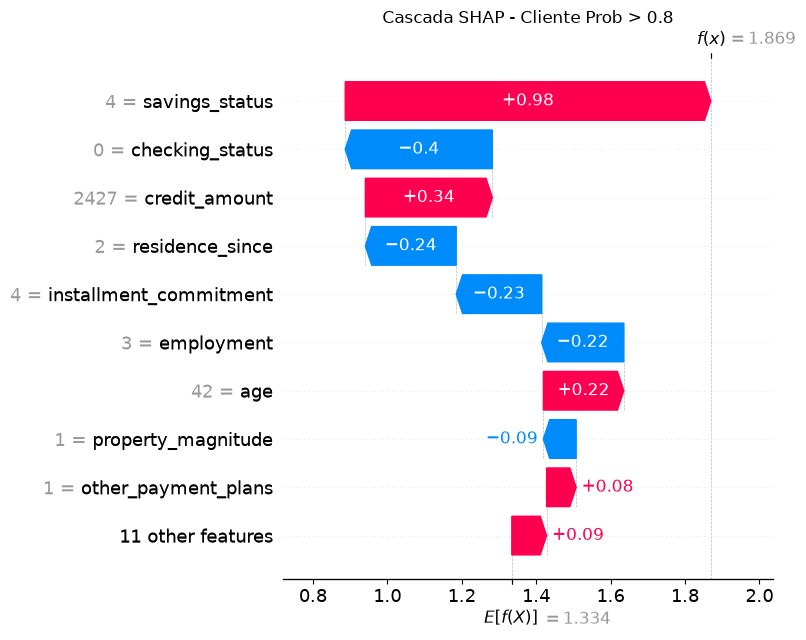


Cliente con probabilidad baja (0.0871)


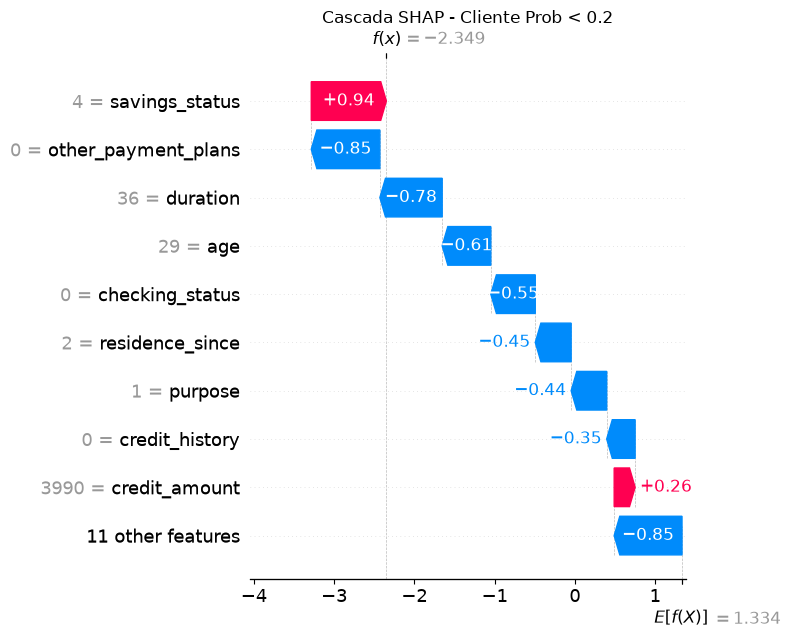


Gráfico Beeswarm Global:


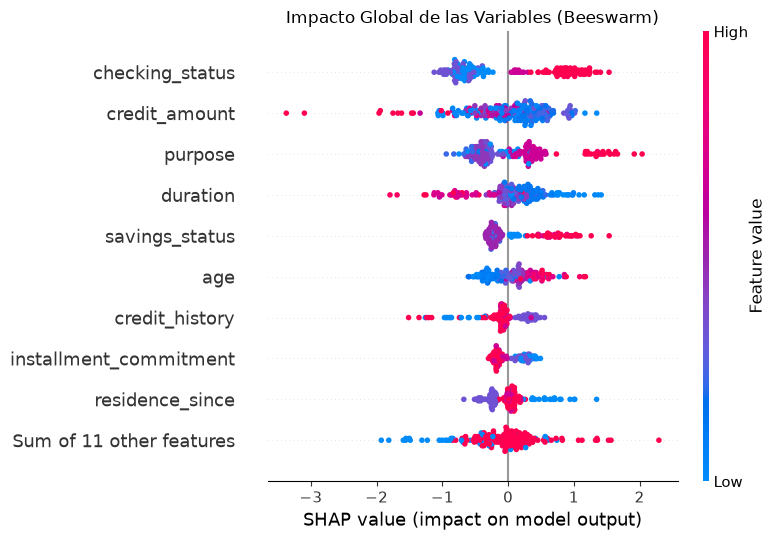

In [6]:
# Diapositiva 8: Los valores de Shapley reparten el merito de una prediccion promediando el aporte marginal de cada variable en todas las coaliciones.
# Diapositiva 9: TreeSHAP permite calcular explicaciones eficientes para arboles y apoya analisis locales y globales en credito, fraude y riesgo.
import shap
import numpy as np
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

print("=== Task 2.2: Análisis con Valores SHAP ===")

# 1. Configurar TreeExplainer intervencional (con fondo) y salida log-odds ('raw')
# Al proveer 'data', shap utiliza por defecto la versión intervencional
explainer = shap.TreeExplainer(
    model=clf, 
    data=X_background, 
    feature_perturbation='interventional', 
    model_output='raw'
)

# Calcular los valores SHAP para el conjunto de prueba
shap_values = explainer(X_test)

# --- a. Verificación de la Eficiencia ---
# Salida esperada en log-odds (scikit-learn decision_function)
log_odds_pred = clf.decision_function(X_test)
# Salida según SHAP: base_value + suma(phi)
shap_pred = shap_values.base_values + shap_values.values.sum(axis=1)

error_eficiencia = np.max(np.abs(log_odds_pred - shap_pred))
print(f"(a) Error absoluto máximo en la verificación de eficiencia: {error_eficiencia:.2e}")

# --- b. Verificación del Valor Base ---
# El valor base de SHAP debe ser el promedio de las predicciones (log-odds) del fondo
base_value_shap = shap_values.base_values[0] # Es el mismo para todas las instancias
mean_log_odds_background = clf.decision_function(X_background).mean()

print(f"(b) Valor base de SHAP: {base_value_shap:.6f}")
print(f"    Promedio log-odds sobre el fondo: {mean_log_odds_background:.6f}")
print(f"    Diferencia absoluta: {abs(base_value_shap - mean_log_odds_background):.2e}")

# --- c. Importancia Global vs Permutación ---
# Importancia global SHAP
importancia_shap = np.abs(shap_values.values).mean(axis=0)
ranking_shap_idx = np.argsort(importancia_shap)[::-1]

# Importancia por permutación
perm_importance = permutation_importance(
    clf, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42
)
importancia_perm = perm_importance.importances_mean
ranking_perm_idx = np.argsort(importancia_perm)[::-1]

print("\n(c) Top 5 variables más importantes:")
print(f"{'Ranking':<8} | {'SHAP Global':<25} | {'Permutación (AUC)':<25}")
print("-" * 65)
features_names = X_test.columns
for i in range(5):
    f_shap = features_names[ranking_shap_idx[i]]
    f_perm = features_names[ranking_perm_idx[i]]
    print(f"#{i+1:<7} | {f_shap:<25} | {f_perm:<25}")

# Correlación de Spearman entre los rankings completos
corr, p_value = spearmanr(importancia_shap, importancia_perm)
print(f"\nCorrelación de Spearman entre los dos rankings: {corr:.4f}")

# --- d. Análisis Local y Global ---
# Probabilidades de la clase 'good'
probabilidades = clf.predict_proba(X_test)[:, 1]

# Encontrar índices de interés
idx_mayor_08 = np.where(probabilidades > 0.8)[0][0] # Primer cliente con prob > 0.8
idx_menor_02 = np.where(probabilidades < 0.2)[0][0] # Primer cliente con prob < 0.2

print("\n(d) Generando gráficos de cascada y beeswarm...")

# Cascada: Cliente > 0.8
plt.figure()
print(f"\nCliente con probabilidad alta ({probabilidades[idx_mayor_08]:.4f})")
shap.plots.waterfall(shap_values[idx_mayor_08], show=False)
plt.title(f"Cascada SHAP - Cliente Prob > 0.8")
plt.tight_layout()
plt.show()

# Cascada: Cliente < 0.2
plt.figure()
print(f"\nCliente con probabilidad baja ({probabilidades[idx_menor_02]:.4f})")
shap.plots.waterfall(shap_values[idx_menor_02], show=False)
plt.title(f"Cascada SHAP - Cliente Prob < 0.2")
plt.tight_layout()
plt.show()

# Beeswarm Global
plt.figure()
print("\nGráfico Beeswarm Global:")
shap.plots.beeswarm(shap_values, show=False)
plt.title("Impacto Global de las Variables (Beeswarm)")
plt.tight_layout()
plt.show()

# Task 2.3

## Task 2.3: Análisis de variables redundantes con SHAP
 
Se evalua cómo se comportan los valores SHAP ante la presencia de variables fuertemente correlacionadas (redundantes). Para ello, identificamos la variable numérica más importante del modelo base del Task 2.2 y creamos una copia de la misma agregándole un pequeño ruido gaussiano ($x_{dup} = x + 0.05\,\sigma_x\,\epsilon$). Reentrenamos el clasificador de Gradient Boosting utilizando la misma semilla pero ahora con 21 variables.

Calculamos las contribuciones SHAP bajo dos enfoques analíticos para observar cómo reparten el mérito:
1. **Intervencional:** Utiliza el conjunto de fondo para romper las dependencias entre variables (aproximando la distribución marginal).
2. **Tree Path Dependent (`tree_path_dependent`):** No utiliza fondo y sigue la ruta de división de los árboles (aproximando la distribución condicional).

In [7]:
# Diapositiva 9: La comparacion de importancias muestra el uso practico de SHAP para interpretar modelos de riesgo mas alla de una sola prediccion.
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import GradientBoostingClassifier

print("=== Task 2.3: Impacto de Variables Redundantes ===")

# 1. Identificar la variable numérica con mayor I_j
# Lista de variables numéricas reales en el dataset credit-g
num_cols = ['duration', 'credit_amount', 'installment_commitment', 
            'residence_since', 'age', 'existing_credits', 'num_dependents']

# Obtener los índices de estas columnas y buscar el que tenga mayor importancia_shap
num_indices = [X.columns.get_loc(c) for c in num_cols]
best_num_idx = max(num_indices, key=lambda idx: importancia_shap[idx])
best_num_col = X.columns[best_num_idx]
I_j_original = importancia_shap[best_num_idx]

print(f"Variable numérica principal: '{best_num_col}' (I_j original: {I_j_original:.4f})")

# 2. Crear la copia con ruido
X_train_dup = X_train.copy()
X_test_dup = X_test.copy()

sigma_x = X_train[best_num_col].std()
np.random.seed(42) # Semilla para el ruido

# Epsilon 
epsilon_train = np.random.randn(len(X_train))
epsilon_test = np.random.randn(len(X_test))

col_dup = f"{best_num_col}_copia"
X_train_dup[col_dup] = X_train[best_num_col] + 0.05 * sigma_x * epsilon_train
X_test_dup[col_dup] = X_test[best_num_col] + 0.05 * sigma_x * epsilon_test

# 3. Reentrenar el modelo con 21 variables
clf_dup = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42)
clf_dup.fit(X_train_dup, y_train)

# 4. SHAP: Configuración Intervencional (con fondo)
X_background_dup = shap.utils.sample(X_train_dup, 100, random_state=42)
explainer_interv = shap.TreeExplainer(
    model=clf_dup, 
    data=X_background_dup, 
    feature_perturbation='interventional', 
    model_output='raw'
)
shap_values_interv = explainer_interv(X_test_dup).values

# 5. SHAP: Configuración Tree Path Dependent (sin fondo)
explainer_path = shap.TreeExplainer(
    model=clf_dup, 
    feature_perturbation='tree_path_dependent', 
    model_output='raw'
)
shap_values_path = explainer_path(X_test_dup).values

# 6. Calcular promedios absolutos |phi|
idx_orig = X_test_dup.columns.get_loc(best_num_col)
idx_dup = X_test_dup.columns.get_loc(col_dup)

# Función auxiliar para calcular medias
def calc_means(shap_vals):
    phi_orig = shap_vals[:, idx_orig]
    phi_copia = shap_vals[:, idx_dup]
    mean_orig = np.abs(phi_orig).mean()
    mean_copia = np.abs(phi_copia).mean()
    mean_sum = np.abs(phi_orig + phi_copia).mean()
    return mean_orig, mean_copia, mean_sum

int_orig, int_copia, int_sum = calc_means(shap_values_interv)
path_orig, path_copia, path_sum = calc_means(shap_values_path)

# 7. Presentar resultados en una tabla
tabla_resultados = pd.DataFrame({
    'Configuración SHAP': ['Intervencional (con fondo)', 'Tree Path Dependent'],
    '|phi| Original': [int_orig, path_orig],
    '|phi| Copia': [int_copia, path_copia],
    '|phi_orig + phi_copia|': [int_sum, path_sum],
    'I_j Original (Modelo Base)': [I_j_original, I_j_original]
})

print("\nResultados de la colinealidad en SHAP:")
display(tabla_resultados.round(4))

=== Task 2.3: Impacto de Variables Redundantes ===
Variable numérica principal: 'credit_amount' (I_j original: 0.4871)

Resultados de la colinealidad en SHAP:


,Configuración SHAP,|phi| Original,|phi| Copia,|phi_orig + phi_copia|,I_j Original (Modelo Base)
0,Intervencional (con fondo),0.3213,0.3333,0.5149,0.4871
1,Tree Path Dependent,0.2983,0.3116,0.5145,0.4871


# Task 2.4: Comparación entre KernelSHAP y TreeSHAP

Se compara la eficiencia y exactitud de dos explicadores distintos: `KernelSHAP` (que aproxima los valores de Shapley mediante un modelo lineal subrogado) y `TreeSHAP` (un algoritmo exacto y polinomial diseñado para modelos basados en árboles). 

Para evaluar las diferencias, se seleccionan 10 instancias del conjunto de prueba y se prueban tres tamaños de fondo distintos, 10, 50 y 100 instancias. Para cada configuración, se calculan los valores SHAP utilizando la salida del modelo en log-odds. En `KernelSHAP`, se especifica un muestreo de 2,000 muestras por instancia para garantizar una buena aproximación. 

Se registra el tiempo de ejecución de cada explicador y se calcula el Error Absoluto Medio (MAE) tomando los valores de `TreeSHAP` intervencional (calculado sobre el mismo fondo) como el valor exacto de referencia, lo que nos permite cuantificar la precisión de la aproximación de KernelSHAP y la ventaja en tiempos de cómputo del explicador de árboles.

In [8]:
# Diapositiva 9: KernelSHAP aproxima los valores de Shapley y TreeSHAP los calcula de forma especializada; el calculo exacto de 2^n coaliciones es inviable.
import time
import shap
import numpy as np
import pandas as pd

print("=== Task 2.4: Comparación KernelSHAP vs TreeSHAP ===")

# 1. Seleccionar 10 instancias de prueba
X_test_10 = X_test.iloc[:10].copy()

# Tamaños de fondo a evaluar según las instrucciones
background_sizes = [10, 50, 100]

resultados_comparacion = []

# Iterar sobre cada tamaño de fondo
for bg_size in background_sizes:
    print(f"\n--- Evaluando con fondo de {bg_size} instancias ---")
    
    # 2. Extraer el fondo de tamaño especificado
    X_bg = shap.utils.sample(X_train, bg_size, random_state=42)
    
    # 3. --- TreeSHAP Intervencional ---
    start_tree = time.time()
    explainer_tree = shap.TreeExplainer(
        model=clf, 
        data=X_bg, 
        feature_perturbation='interventional', 
        model_output='raw'
    )
    # Extraemos solo los valores numéricos con .values
    shap_values_tree = explainer_tree(X_test_10).values 
    time_tree = time.time() - start_tree
    
    # 4. --- KernelSHAP ---
    # Pasamos la función que devuelve log-odds (decision_function para GradientBoostingClassifier)
    start_kernel = time.time()
    explainer_kernel = shap.KernelExplainer(
        model=clf.decision_function, 
        data=X_bg
    )
    
    # KernelExplainer.shap_values suele mostrar una barra de progreso, 
    # usamos silent=True si es posible o simplemente calculamos con 2000 nsamples
    shap_values_kernel = explainer_kernel.shap_values(X_test_10, nsamples=2000, silent=True)
    time_kernel = time.time() - start_kernel
    
    # 5. Calcular Error Absoluto Medio (MAE)
    mae = np.mean(np.abs(shap_values_tree - shap_values_kernel))
    
    print(f"Tiempo TreeSHAP: {time_tree:.4f} s")
    print(f"Tiempo KernelSHAP: {time_kernel:.4f} s")
    print(f"Error Absoluto Medio (MAE): {mae:.4e}")
    
    resultados_comparacion.append({
        'Fondo': bg_size,
        'Tiempo TreeSHAP (s)': time_tree,
        'Tiempo KernelSHAP (s)': time_kernel,
        'MAE': mae
    })

# Mostrar tabla resumen de los resultados
df_resumen = pd.DataFrame(resultados_comparacion)
print("\nResumen de la comparación:")
display(df_resumen.round(6))

=== Task 2.4: Comparación KernelSHAP vs TreeSHAP ===

--- Evaluando con fondo de 10 instancias ---
Tiempo TreeSHAP: 0.0139 s
Tiempo KernelSHAP: 0.8668 s
Error Absoluto Medio (MAE): 3.3860e-02

--- Evaluando con fondo de 50 instancias ---
Tiempo TreeSHAP: 0.0228 s
Tiempo KernelSHAP: 2.4206 s
Error Absoluto Medio (MAE): 3.9121e-02

--- Evaluando con fondo de 100 instancias ---
Tiempo TreeSHAP: 0.0234 s
Tiempo KernelSHAP: 5.7245 s
Error Absoluto Medio (MAE): 3.1422e-02

Resumen de la comparación:


,Fondo,Tiempo TreeSHAP (s),Tiempo KernelSHAP (s),MAE
0,10,0.013933,0.866794,0.033860
1,50,0.022825,2.420552,0.039121
2,100,0.023365,5.724455,0.031422


# Task 2.5

## Task 2.5: Implementación de la fórmula de Shapley desde cero

Se calcula los valores SHAP desde cero aplicando la fórmula original de Shapley, la cual reparte el mérito de una predicción evaluando el aporte marginal de cada variable a través de todas las coaliciones posibles. 

Para hacer el cálculo entrenamos un nuevo modelo `GradientBoostingClassifier` utilizando únicamente 6 variables numéricas (`duration`, `credit_amount`, `installment_commitment`, `residence_since`, `age`, `existing_credits`) y utilizamos un fondo de 50 instancias.

El cálculo manual para 5 instancias de prueba procede de la siguiente manera:
*   **(a)** Se define la función de valor $v(S)$ como el promedio de la salida del modelo (en log-odds) sobre el conjunto de fondo, fijando los valores de las variables que pertenecen a la coalición $S$ con los de la instancia analizada, y tomando los valores de las demás variables del fondo.
*   **(b)** Se iteran las $2^6 = 64$ coaliciones posibles y se calcula cada $\phi_i$ acumulando los aportes marginales $v(S \cup \{i\}) - v(S)$ multiplicados por su respectivo peso factorial.
*   **(c)** se contrastan los valores calculados manualmente con los de `TreeSHAP` intervencional, verificando que la suma de los $\phi_i$ cumpla con el axioma de eficiencia sumando exactamente $v(N) - v(\varnothing)$.

In [9]:
# Diapositiva 8: Esta implementacion reproduce la formula matematica de Shapley evaluando coaliciones y aportes marginales.
import numpy as np
import pandas as pd
import shap
import math
from itertools import combinations
from sklearn.ensemble import GradientBoostingClassifier

print("=== Task 2.5: Fórmula de Shapley desde cero ===")

# 1. Preparar datos con solo 6 variables numéricas
cols_6 = ['duration', 'credit_amount', 'installment_commitment', 
          'residence_since', 'age', 'existing_credits']

X_train_6 = X_train[cols_6].copy()
X_test_6 = X_test[cols_6].copy()

# 2. Entrenar el nuevo modelo
clf_6 = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42)
clf_6.fit(X_train_6, y_train)

# 3. Preparar el fondo (50 instancias) y el conjunto de prueba (5 instancias)
X_bg_6 = shap.utils.sample(X_train_6, 50, random_state=42)
X_test_5 = X_test_6.iloc[:5].copy()

# Variables globales para la función de valor
fondo_arr = X_bg_6.values
N = len(cols_6)

# --- a. Definir v(S) ---
def v(S_indices, instance_arr):
    """
    Calcula el valor v(S) promediando las predicciones sobre el fondo.
    S_indices: lista de índices (0 a 5) de las variables en la coalición S.
    instance_arr: valores de la instancia analizada.
    """
    if len(S_indices) == 0:
        # Si S es vacío, devuelve el promedio sobre el fondo inalterado
        return clf_6.decision_function(fondo_arr).mean()
    
    # Crear una matriz combinada: copiar el fondo
    blend = fondo_arr.copy()
    # Reemplazar las columnas en S con los valores de la instancia
    for idx in S_indices:
        blend[:, idx] = instance_arr[idx]
        
    # Promedio de las predicciones en log-odds
    return clf_6.decision_function(blend).mean()

# --- b. Cálculo de phi_i para las 64 coaliciones ---
def calcular_shapley_manual(instance_arr):
    phis = np.zeros(N)
    v_empty = v([], instance_arr)
    v_all = v(list(range(N)), instance_arr)
    
    # Cache para evitar recalcular v(S) repetidas veces
    v_cache = {}
    
    for i in range(N):
        phi_i = 0.0
        # Conjunto de variables excluyendo 'i'
        subset_without_i = [x for x in range(N) if x != i]
        
        # Iterar sobre todos los tamaños de coalición posibles (0 a N-1)
        for size in range(N):
            for S in combinations(subset_without_i, size):
                S_list = list(S)
                S_union_i = S_list + [i]
                
                # Ordenar para usar como llave en caché
                S_tuple = tuple(sorted(S_list))
                S_union_tuple = tuple(sorted(S_union_i))
                
                if S_tuple not in v_cache:
                    v_cache[S_tuple] = v(S_list, instance_arr)
                if S_union_tuple not in v_cache:
                    v_cache[S_union_tuple] = v(S_union_i, instance_arr)
                    
                val_S = v_cache[S_tuple]
                val_S_union_i = v_cache[S_union_tuple]
                
                # Peso factorial: |S|! (N - |S| - 1)! / N!
                peso = (math.factorial(len(S_list)) * math.factorial(N - len(S_list) - 1)) / math.factorial(N)
                
                # Acumular aporte marginal
                phi_i += peso * (val_S_union_i - val_S)
                
        phis[i] = phi_i
        
    return phis, v_empty, v_all

# Ejecutar el cálculo manual para las 5 instancias
phis_manuales = []
eficiencias = []

print("Calculando valores Shapley manualmente para 5 instancias...")
for idx in range(len(X_test_5)):
    instancia = X_test_5.iloc[idx].values
    phi_manual, v_vacio, v_completo = calcular_shapley_manual(instancia)
    phis_manuales.append(phi_manual)
    
    # Comprobar eficiencia manual: sum(phi_i) == v(N) - v(vacío)
    suma_phi = np.sum(phi_manual)
    diferencia_v = v_completo - v_vacio
    error_ef = abs(suma_phi - diferencia_v)
    eficiencias.append(error_ef)

phis_manuales = np.array(phis_manuales)

# --- c. Comparación con TreeSHAP Intervencional ---
explainer_6 = shap.TreeExplainer(
    model=clf_6, 
    data=X_bg_6, 
    feature_perturbation='interventional', 
    model_output='raw'
)
shap_values_6 = explainer_6(X_test_5).values

# Calcular el error máximo entre nuestra implementación y la de SHAP
error_maximo = np.max(np.abs(phis_manuales - shap_values_6))

print("\nResultados de la Verificación:")
print(f"(c) Error absoluto máximo frente a TreeSHAP intervencional: {error_maximo:.4e}")
print(f"(c) Error máximo en el axioma de eficiencia de los phi manuales: {max(eficiencias):.4e}")

# Mostrar los valores para la primera instancia como ejemplo
df_ejemplo = pd.DataFrame({
    'Variable': cols_6,
    'SHAP Manual': phis_manuales[0],
    'TreeSHAP': shap_values_6[0],
    'Diferencia': np.abs(phis_manuales[0] - shap_values_6[0])
})
print("\nEjemplo detallado para la Instancia 1:")
display(df_ejemplo.round(6))

=== Task 2.5: Fórmula de Shapley desde cero ===
Calculando valores Shapley manualmente para 5 instancias...

Resultados de la Verificación:
(c) Error absoluto máximo frente a TreeSHAP intervencional: 2.1303e-08
(c) Error máximo en el axioma de eficiencia de los phi manuales: 7.7716e-16

Ejemplo detallado para la Instancia 1:


C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCac

,Variable,SHAP Manual,TreeSHAP,Diferencia
0,duration,-0.391387,-0.391387,0.0
1,credit_amount,0.424931,0.424931,0.0
2,installment_commitment,-0.046387,-0.046387,0.0
3,residence_since,-0.143532,-0.143532,0.0
4,age,0.309065,0.309065,0.0
5,existing_credits,0.099450,0.099450,0.0


# Task 2.6

## Task 2.6: Análisis de propiedades matemáticas y computacionales de SHAP

Se analizan analíticamente las propiedades y limitaciones de los valores SHAP basados en los resultados previos:

*   **(a) No linealidad en probabilidad:** Para el cliente rechazado (probabilidad baja) del Task 2.2, se transforma la salida de log-odds a probabilidad utilizando la función sigmoide $p(x) = \sigma(f(x))$. Se calcula el efecto marginal aislado de cada variable en el espacio de probabilidad y se suma, demostrando numéricamente por qué SHAP garantiza aditividad exacta solo en el espacio del margen (log-odds) y no al pasar por funciones no lineales.
*   **(b) Importancia SHAP vs. Permutación:** Se compara sistemáticamente el ranking de importancia global de SHAP frente al de permutación para identificar la variable con mayor discrepancia. Se analiza su correlación con otras variables para evidenciar cómo cada métrica lidia de forma distinta con la colinealidad estructural.
*   **(c) Axiomas y dependencias (Análisis teórico):** Se explicará cómo el modelo y el explicador manejan la simetría y la redundancia con base en los resultados del Task 2.3, contrastando la versión marginal (intervencional) con la aproximación condicional (`tree_path_dependent`).
*   **(d) Complejidad computacional:** Utilizando los tiempos de predicción del modelo sobre un fondo de 100 instancias, se estima el tiempo requerido para calcular un Shapley exacto ($2^{20}$ evaluaciones para 20 variables). Se dimensiona matemáticamente el costo de la explosión combinatoria al extrapolar el cálculo a 60 variables a un microsegundo por evaluación.

In [10]:
# Diapositiva 9: La implementacion desde cero permite observar el costo computacional del calculo exacto frente a los metodos aproximados.
import numpy as np
import pandas as pd
import time
from scipy.stats import spearmanr

print("=== Task 2.6: Análisis Matemático y Computacional ===")

# --- a. Cliente rechazado y no linealidad de la probabilidad ---
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Utilizamos el índice del cliente rechazado del Task 2.2
phi_0 = shap_values.base_values[idx_menor_02]
phis_j = shap_values.values[idx_menor_02]
f_x = phi_0 + np.sum(phis_j)

p_x = sigmoid(f_x)
p_base = sigmoid(phi_0)
efecto_real = p_x - p_base

# Efecto individual simulado en el espacio de probabilidad
efectos_individuales = sigmoid(phi_0 + phis_j) - sigmoid(phi_0)
suma_efectos_individuales = np.sum(efectos_individuales)

print("\n[Inciso a] Aditividad en probabilidad (Cliente rechazado)")
print(f"Probabilidad base sigma(phi_0): {p_base:.4f}")
print(f"Probabilidad final p(x): {p_x:.4f}")
print(f"Efecto total real [p(x) - sigma(phi_0)]: {efecto_real:.4f}")
print(f"Suma de efectos individuales aislados: {suma_efectos_individuales:.4f}")

# --- b. Diferencia de ranking entre SHAP y Permutación ---
# Calcular posiciones en el ranking (0 es el más importante)
ranking_shap = np.argsort(np.argsort(importancia_shap)[::-1])
ranking_perm = np.argsort(np.argsort(importancia_perm)[::-1])

# Buscar la variable con mayor salto en los rankings
diferencias = np.abs(ranking_shap - ranking_perm)
idx_max_diff = np.argmax(diferencias)
var_max_diff = X_test.columns[idx_max_diff]

print(f"\n[Inciso b] Variable con mayor diferencia de ranking: '{var_max_diff}'")
print(f"Posición en SHAP Global: {ranking_shap[idx_max_diff] + 1}")
print(f"Posición en Permutación: {ranking_perm[idx_max_diff] + 1}")

# Calcular correlaciones de Spearman en el conjunto de entrenamiento para esta variable
correlaciones = X_train.corr(method='spearman')[var_max_diff].drop(var_max_diff)
print(f"\nTop 3 correlaciones (Spearman) de '{var_max_diff}' con otras variables:")
print(correlaciones.abs().sort_values(ascending=False).head(3))

# --- d. Complejidad y explosión combinatoria ---
print("\n[Inciso d] Estimaciones Computacionales de Shapley Exacto")

# 1. Medir el tiempo base de una evaluación v(S) (predicción sobre 100 instancias de fondo)
start_time = time.time()
_ = clf.predict_proba(X_background)
t_100_preds = time.time() - start_time
print(f"Tiempo base para 1 evaluación v(S) (predecir fondo de 100): {t_100_preds:.6e} s")

# 2. Estimar tiempo para Shapley exacto de 1 instancia con 20 variables
evals_20 = 2**20 # 1,048,576 evaluaciones
tiempo_exacto_20 = evals_20 * t_100_preds
print(f"Evaluaciones necesarias para 20 variables: {evals_20:,}")
print(f"Tiempo estimado (Shapley Exacto 20 vars): {tiempo_exacto_20:.2f} s ({tiempo_exacto_20/60:.2f} min)")

# 3. Calcular en años el tiempo para 60 variables a 1 microsegundo por evaluación
evals_60 = 2**60
tiempo_60_segundos = evals_60 * 1e-6 # 1 microsegundo = 1e-6 s
tiempo_60_anios = tiempo_60_segundos / (60 * 60 * 24 * 365.25)
print(f"\nEvaluaciones necesarias para 60 variables: {evals_60:,}")
print(f"Tiempo estimado (60 vars a 1 us/eval): {tiempo_60_anios:.2e} años")

=== Task 2.6: Análisis Matemático y Computacional ===

[Inciso a] Aditividad en probabilidad (Cliente rechazado)
Probabilidad base sigma(phi_0): 0.7916
Probabilidad final p(x): 0.0871
Efecto total real [p(x) - sigma(phi_0)]: -0.7044
Suma de efectos individuales aislados: -0.7744

[Inciso b] Variable con mayor diferencia de ranking: 'age'
Posición en SHAP Global: 6
Posición en Permutación: 20

Top 3 correlaciones (Spearman) de 'age' con otras variables:
housing            0.312011
employment         0.306383
personal_status    0.272981
Name: age, dtype: float64

[Inciso d] Estimaciones Computacionales de Shapley Exacto
Tiempo base para 1 evaluación v(S) (predecir fondo de 100): 2.589464e-03 s
Evaluaciones necesarias para 20 variables: 1,048,576
Tiempo estimado (Shapley Exacto 20 vars): 2715.25 s (45.25 min)

Evaluaciones necesarias para 60 variables: 1,152,921,504,606,846,976
Tiempo estimado (60 vars a 1 us/eval): 3.65e+04 años


# Task 3

## Task 3.1: Implementación de LIME desde cero
Se implementa Local Interpretable Model-agnostic Explanations (LIME) para datos tabulares sin recurrir a la librería oficial. La técnica aproxima el comportamiento del clasificador complejo alrededor de una instancia específica utilizando un modelo lineal interpretable y localmente ponderado.

El proceso sigue los siguientes pasos definidos:
1. **Representación:** Se generan $N = 5000$ muestras binarias $z'$. Si el valor es 1, la variable conserva el valor original del cliente, si es 0, toma un valor aleatorio de la distribución de entrenamiento para esa variable.
2. **Ponderación:** Se define el peso de cada muestra con un kernel exponencial $\pi_x(z) = \exp(-D^2/\sigma^2)$, donde el ancho del kernel usa $\sigma_{rel} = 0.75$.
3. **Ajuste y Selección:** Se resuelve algebraicamente la regresión Ridge (Weighted Least Squares con regularización $\lambda = 1.0$). Para la penalización se añadió una columna de unos a la matriz para calcular el intercepto, pero la matriz identidad regularizadora $I$ se modificó asignando un $0$ en la posición $[0,0]$. Esto significa que el intercepto no fue penalizado, garantizando que el sesgo base no se reduzca artificialmente hacia cero.
4. **Explicación Local:** Se extraen las $K = 5$ variables con mayor coeficiente absoluto $|w|$, se vuelve a ajustar la regresión únicamente con ellas y se calcula la fidelidad $R_w^2$ para medir qué tan bien aproxima este modelo simple al complejo en esa vecindad.

El algoritmo se aplica a tres clientes específicos: probabilidad alta ($>0.8$), baja (rechazado, $<0.2$) y de frontera (entre $0.45$ y $0.55$).

In [11]:
# Diapositiva 9: Las propiedades matematicas de SHAP muestran por que sus explicaciones son utiles para decisiones locales y globales, aunque requieren validacion.
import numpy as np
import pandas as pd

print("=== Task 3.1: LIME Tabular desde cero ===")

# --- Parámetros de LIME ---
N = 5000
K = 5
lam = 1.0
sigma_rel = 0.75
d_prime = 20
sigma = sigma_rel * np.sqrt(d_prime)
sigma_sq = sigma ** 2

# Valores del conjunto de entrenamiento para el muestreo aleatorio
X_train_vals = X_train.values

# --- Función Principal de LIME ---
def calcular_lime_manual(instancia_x):
    # 1. Generar N vectores binarios z' (probabilidad 0.5)
    np.random.seed(42) # Reproducibilidad
    Z_prime = np.random.binomial(1, 0.5, size=(N, d_prime))
    
    # Asegurar que la primera muestra sea la instancia original sin perturbar (convención de LIME)
    Z_prime[0, :] = 1.0 
    
    # Construir la entrada perturbada Z
    Z = np.zeros((N, d_prime))
    for j in range(d_prime):
        # Muestreo aleatorio de la columna j desde los datos de entrenamiento
        valores_aleatorios = np.random.choice(X_train_vals[:, j], size=N)
        # Si z'_j == 1, conserva el valor de x. Si es 0, toma el valor aleatorio.
        Z[:, j] = np.where(Z_prime[:, j] == 1, instancia_x[j], valores_aleatorios)
        
    # 2. Salida a explicar: probabilidad de 'good'
    y_lime = clf.predict_proba(Z)[:, 1]
    
    # Calcular pesos pi_x(z)
    # D^2 es el número de variables ausentes (donde z' == 0)
    D_sq = d_prime - np.sum(Z_prime, axis=1)
    pi_z = np.exp(-D_sq / sigma_sq)
    
    # Función para ajustar Regresión Ridge Ponderada
    def fit_weighted_ridge(Z_mat, y_vec, weights):
        num_muestras, num_vars = Z_mat.shape
        # Añadir columna de unos para el intercepto
        Z_bias = np.c_[np.ones(num_muestras), Z_mat]
        
        # Calcular matrices (Z'^T * Pi * Z') y (Z'^T * Pi * y)
        # Multiplicar las filas de Z_bias por sus pesos pi correspondientes
        Z_pi = Z_bias * weights[:, np.newaxis]
        A = Z_bias.T @ Z_pi
        b = Z_pi.T @ y_vec
        
        # Matriz de regularización lambda * I
        I_mat = np.eye(num_vars + 1)
        I_mat[0, 0] = 0.0 # ¡No penalizar el intercepto!
        
        # Solución cerrada: w = (Z'^T Pi Z' + lambda I)^(-1) Z'^T Pi y
        w = np.linalg.inv(A + lam * I_mat) @ b
        return w
    
    # 3. Primer ajuste con las 20 variables
    w_all = fit_weighted_ridge(Z_prime, y_lime, pi_z)
    w_coefs = w_all[1:] # Ignorar intercepto para el ranking
    
    # Seleccionar las K variables con mayor |w|
    top_k_idx = np.argsort(np.abs(w_coefs))[-K:][::-1]
    
    # 4. Segundo ajuste solo con las K variables retenidas
    Z_prime_k = Z_prime[:, top_k_idx]
    w_k = fit_weighted_ridge(Z_prime_k, y_lime, pi_z)
    
    intercepto_final = w_k[0]
    coefs_finales = w_k[1:]
    
    # Nombres de las K variables
    nombres_k = X_test.columns[top_k_idx]
    
    # Calcular Fidelidad R_w^2
    Z_k_bias = np.c_[np.ones(N), Z_prime_k]
    pred_g = Z_k_bias @ w_k # g_n
    
    y_bar_w = np.sum(pi_z * y_lime) / np.sum(pi_z)
    
    numerador = np.sum(pi_z * (y_lime - pred_g)**2)
    denominador = np.sum(pi_z * (y_lime - y_bar_w)**2)
    R2_w = 1.0 - (numerador / denominador)
    
    return intercepto_final, nombres_k, coefs_finales, R2_w

# --- Selección de Clientes de Prueba ---
probabilidades_test = clf.predict_proba(X_test)[:, 1]

# Cliente con prob > 0.8 (mismo del task 2.2)
idx_alto = np.where(probabilidades_test > 0.8)[0][0]

# Cliente rechazado del task 2.2 (prob < 0.2)
idx_bajo = np.where(probabilidades_test < 0.2)[0][0]

# Cliente frontera (0.45 < prob < 0.55)
idx_medio = np.where((probabilidades_test > 0.45) & (probabilidades_test < 0.55))[0][0]

clientes_evaluar = {
    'Cliente A (Prob > 0.8)': idx_alto,
    'Cliente B (Prob < 0.2 - Rechazado)': idx_bajo,
    'Cliente C (0.45 < Prob < 0.55)': idx_medio
}

# --- Aplicar LIME a los clientes ---
for nombre, idx_cliente in clientes_evaluar.items():
    instancia_cliente = X_test.iloc[idx_cliente].values
    prob_modelo = probabilidades_test[idx_cliente]
    
    intercepto, variables, coeficientes, r2 = calcular_lime_manual(instancia_cliente)
    
    print(f"\n--- {nombre} ---")
    print(f"Probabilidad del modelo complejo: {prob_modelo:.4f}")
    print(f"Fidelidad ponderada R_w^2: {r2:.4f}")
    print(f"Intercepto LIME: {intercepto:.4f}")
    print("Coeficientes de las 5 variables principales (K):")
    for var, coef in zip(variables, coeficientes):
        print(f"  {var:<25} : {coef:+.4f}")

=== Task 3.1: LIME Tabular desde cero ===

--- Cliente A (Prob > 0.8) ---
Probabilidad del modelo complejo: 0.8664
Fidelidad ponderada R_w^2: 0.1835
Intercepto LIME: 0.6933
Coeficientes de las 5 variables principales (K):
  savings_status            : +0.1455
  credit_amount             : +0.0851
  checking_status           : -0.0516
  residence_since           : -0.0454
  installment_commitment    : -0.0366

--- Cliente B (Prob < 0.2 - Rechazado) ---
Probabilidad del modelo complejo: 0.0871
Fidelidad ponderada R_w^2: 0.2377
Intercepto LIME: 0.5565
Coeficientes de las 5 variables principales (K):
  savings_status            : +0.1485
  other_payment_plans       : -0.1339
  duration                  : -0.1265
  age                       : -0.1149
  checking_status           : -0.0954

--- Cliente C (0.45 < Prob < 0.55) ---
Probabilidad del modelo complejo: 0.4663
Fidelidad ponderada R_w^2: 0.1542
Intercepto LIME: 0.6997
Coeficientes de las 5 variables principales (K):
  checking_status 

C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


# Task 3.2: Estabilidad de LIME

LIME se basa en un muestreo aleatorio en la vecindad de la instancia a explicar. Esto introduce una varianza intrínseca: corridas distintas pueden producir explicaciones diferentes si el tamaño de la muestra ($N$) no es suficientemente grande o si el ancho del kernel ($\sigma_{rel}$) es demasiado estrecho, limitando la cantidad de instancias con peso relevante.

Se evalúa cuantitativamente la estabilidad de las explicaciones generadas para el cliente rechazado del Task 2.2. Para cada combinación de tamaño de muestra $N \in \{500, 2000, 5000\}$ y ancho relativo de kernel $\sigma_{rel} \in \{0.5, 0.75, 1.5\}$, se ejecuta el algoritmo LIME 20 veces utilizando semillas aleatorias distintas. 

Se calculan dos métricas principales:
1. **Índice de Jaccard Promedio:** Mide qué tan consistentes son las $K=5$ variables principales seleccionadas. Se calcula el índice de Jaccard $J(A,B) = \frac{|A \cap B|}{|A \cup B|}$ para todos los pares de las 20 corridas y se promedia. Un valor de 1 indica estabilidad perfecta (siempre se eligen las mismas 5 variables), mientras que un valor menor indica inestabilidad.
2. **Tamaño Efectivo de Muestra ($N_{ef}$):** Mide la cantidad de muestras que realmente importan en la regresión ponderada, calculado como $N_{ef} = \frac{(\sum \pi_n)^2}{\sum \pi_n^2}$. Si $\sigma_{rel}$ es muy pequeño, los pesos decaen tan rápido que la regresión se ajusta utilizando efectivamente solo un puñado de instancias, aumentando la inestabilidad matemática.

In [12]:
# Diapositiva 10: LIME ajusta un modelo lineal interpretable en la vecindad local usando muestras perturbadas y ponderadas.
import numpy as np
import pandas as pd
from itertools import combinations

print("=== Task 3.2: Medición de Estabilidad en LIME ===")

# --- Parámetros Base ---
K = 5
lam = 1.0
d_prime = 20
num_corridas = 20

lista_N = [500, 2000, 5000]
lista_sigma_rel = [0.5, 0.75, 1.5]

# Extraer el cliente rechazado (mismo que Task 3.1)
instancia_cliente = X_test.iloc[idx_bajo].values
X_train_vals = X_train.values
columnas = X_test.columns

# Estructuras para guardar resultados
resultados_jaccard = np.zeros((len(lista_N), len(lista_sigma_rel)))
resultados_nef = np.zeros((len(lista_N), len(lista_sigma_rel)))

# Función para calcular LIME rápido para el loop
def lime_loop(N_muestras, sig_rel, seed):
    sigma = sig_rel * np.sqrt(d_prime)
    sigma_sq = sigma ** 2
    
    # Muestreo
    np.random.seed(seed)
    Z_prime = np.random.binomial(1, 0.5, size=(N_muestras, d_prime))
    Z_prime[0, :] = 1.0 
    
    # Pesos y Nef
    D_sq = d_prime - np.sum(Z_prime, axis=1)
    pi_z = np.exp(-D_sq / sigma_sq)
    N_ef = (np.sum(pi_z)**2) / np.sum(pi_z**2)
    
    # Reconstruir datos para predecir
    Z = np.zeros((N_muestras, d_prime))
    for j in range(d_prime):
        valores_aleatorios = np.random.choice(X_train_vals[:, j], size=N_muestras)
        Z[:, j] = np.where(Z_prime[:, j] == 1, instancia_cliente[j], valores_aleatorios)
        
    y_lime = clf.predict_proba(Z)[:, 1]
    
    # Ajuste de regresión Ridge ponderada (sobre las 20 variables)
    Z_bias = np.c_[np.ones(N_muestras), Z_prime]
    Z_pi = Z_bias * pi_z[:, np.newaxis]
    
    A = Z_bias.T @ Z_pi
    b = Z_pi.T @ y_lime
    
    I_mat = np.eye(d_prime + 1)
    I_mat[0, 0] = 0.0 # No penalizar intercepto
    
    w_all = np.linalg.inv(A + lam * I_mat) @ b
    w_coefs = w_all[1:]
    
    # Seleccionar las K variables
    top_k_idx = np.argsort(np.abs(w_coefs))[-K:][::-1]
    top_k_names = set(columnas[top_k_idx])
    
    return top_k_names, N_ef

print("Ejecutando combinaciones (esto puede tomar un momento)...")

# --- Loop Principal ---
for i, n_val in enumerate(lista_N):
    for j, sig_val in enumerate(lista_sigma_rel):
        
        conjuntos_top_k = []
        valores_nef = []
        
        # Ejecutar 20 veces con semillas distintas
        for s in range(num_corridas):
            top_vars, n_ef = lime_loop(n_val, sig_val, seed=s)
            conjuntos_top_k.append(top_vars)
            valores_nef.append(n_ef)
            
        # Calcular Jaccard promedio entre todos los pares (20C2 = 190 pares)
        jaccards_pares = []
        for set_A, set_B in combinations(conjuntos_top_k, 2):
            interseccion = len(set_A.intersection(set_B))
            union = len(set_A.union(set_B))
            jaccards_pares.append(interseccion / union)
            
        resultados_jaccard[i, j] = np.mean(jaccards_pares)
        resultados_nef[i, j] = np.mean(valores_nef)

# --- Construir y mostrar tablas ---
df_jaccard = pd.DataFrame(
    resultados_jaccard, 
    index=[f"N={n}" for n in lista_N], 
    columns=[f"σ_rel={s}" for s in lista_sigma_rel]
)

df_nef = pd.DataFrame(
    resultados_nef, 
    index=[f"N={n}" for n in lista_N], 
    columns=[f"σ_rel={s}" for s in lista_sigma_rel]
)

print("\n--- Índice de Jaccard Promedio (Estabilidad) ---")
display(df_jaccard.round(4))

print("\n--- Tamaño Efectivo de Muestra Promedio (N_ef) ---")
display(df_nef.round(2))

=== Task 3.2: Medición de Estabilidad en LIME ===
Ejecutando combinaciones (esto puede tomar un momento)...


C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCac


--- Índice de Jaccard Promedio (Estabilidad) ---


C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCac

,σ_rel=0.5,σ_rel=0.75,σ_rel=1.5
N=500,0.5857,0.5898,0.5960
N=2000,0.8308,0.7604,0.7604
N=5000,0.8386,0.9667,0.9667



--- Tamaño Efectivo de Muestra Promedio (N_ef) ---


,σ_rel=0.5,σ_rel=0.75,σ_rel=1.5
N=500,391.49,478.98,498.70
N=2000,1622.35,1921.23,1995.01
N=5000,4082.91,4804.94,4987.59


# Task 3.3: Comparación entre LIME y SHAP

Se compara directamente las explicaciones locales generadas por LIME frente a las atribuciones exactas de `TreeSHAP` (Task 2.2).

*   **(a) Correlación y Coincidencia:** Para los tres clientes analizados en el Task 3.1 (probabilidad alta, rechazada y frontera), se calcula la correlación de Spearman entre el valor absoluto de los coeficientes de LIME obtenidos al ajustar con las 20 variables ($\vert{}w\vert{}$) y la magnitud absoluta de los valores SHAP correspondientes ($\vert{}\phi\vert{}$). También se mide cuántas de las 3 variables principales coinciden en ambos métodos, evaluando si priorizan las mismas características a pesar de sus diferencias matemáticas.
*   **(b) Fidelidad vs. Interpretabilidad:** Para el cliente rechazado, se varia el número de variables retenidas por LIME evaluando $K \in \{3, 5, 10, 20\}$. Se calcula la fidelidad ponderada local ($R_w^2$) para cada $K$ a fin de observar el compromiso (*trade-off*) entre tener una explicación simple (pocas variables) y una que aproxime correctamente el comportamiento local del modelo complejo.

In [13]:
# Diapositiva 10: La estabilidad de LIME depende del muestreo de la vecindad; variaciones en las perturbaciones pueden cambiar la explicacion local.
# Diapositiva 15: La estabilidad es un criterio de confianza para no aceptar explicaciones que cambian arbitrariamente.
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

print("=== Task 3.3: Comparación LIME vs SHAP ===")

# Utilizaremos las mismas variables y la lógica de muestreo del Task 3.1
N = 5000
lam = 1.0
sigma_rel = 0.75
d_prime = 20
sigma = sigma_rel * np.sqrt(d_prime)
sigma_sq = sigma ** 2

# Función auxiliar para generar el muestreo base y pesos de LIME de un cliente
def generar_datos_lime(instancia_x):
    np.random.seed(42)
    Z_prime = np.random.binomial(1, 0.5, size=(N, d_prime))
    Z_prime[0, :] = 1.0 
    
    Z = np.zeros((N, d_prime))
    for j in range(d_prime):
        valores_aleatorios = np.random.choice(X_train_vals[:, j], size=N)
        Z[:, j] = np.where(Z_prime[:, j] == 1, instancia_x[j], valores_aleatorios)
        
    y_lime = clf.predict_proba(Z)[:, 1]
    
    D_sq = d_prime - np.sum(Z_prime, axis=1)
    pi_z = np.exp(-D_sq / sigma_sq)
    
    return Z_prime, y_lime, pi_z

# Función para ajuste de regresión
def fit_weighted_ridge(Z_mat, y_vec, weights):
    num_muestras, num_vars = Z_mat.shape
    Z_bias = np.c_[np.ones(num_muestras), Z_mat]
    Z_pi = Z_bias * weights[:, np.newaxis]
    A = Z_bias.T @ Z_pi
    b = Z_pi.T @ y_vec
    I_mat = np.eye(num_vars + 1)
    I_mat[0, 0] = 0.0 # No penalizar intercepto
    return np.linalg.inv(A + lam * I_mat) @ b

# --- a. Correlación y coincidencia para los 3 clientes ---
print("\n[Inciso a] Correlación Spearman y Coincidencia Top 3")

for nombre, idx_cliente in clientes_evaluar.items():
    instancia = X_test.iloc[idx_cliente].values
    
    # 1. Ejecutar LIME para obtener pesos con las 20 variables
    Z_prime, y_lime, pi_z = generar_datos_lime(instancia)
    w_all = fit_weighted_ridge(Z_prime, y_lime, pi_z)
    w_coefs = w_all[1:] # Ignorar intercepto
    abs_w = np.abs(w_coefs)
    
    # 2. Obtener valores SHAP absolutos del Task 2.2
    # shap_values.values tiene dimensiones (n_muestras, n_variables)
    phi_shap = shap_values.values[idx_cliente]
    abs_phi = np.abs(phi_shap)
    
    # 3. Correlación de Spearman entre rankings completos
    corr, p_value = spearmanr(abs_w, abs_phi)
    
    # 4. Coincidencia en las 3 variables principales
    top3_lime = set(np.argsort(abs_w)[-3:])
    top3_shap = set(np.argsort(abs_phi)[-3:])
    coincidencia = len(top3_lime.intersection(top3_shap))
    
    # Nombres para mostrar
    nombres_top_lime = [X_test.columns[i] for i in top3_lime]
    nombres_top_shap = [X_test.columns[i] for i in top3_shap]
    
    print(f"\n- {nombre}:")
    print(f"  Correlación Spearman (|w| vs |phi|): {corr:.4f}")
    print(f"  Coincidencia en Top 3: {coincidencia} de 3 variables")
    print(f"  Top 3 LIME: {nombres_top_lime}")
    print(f"  Top 3 SHAP: {nombres_top_shap}")

# --- b. Fidelidad Rw^2 para distintos valores de K (Cliente Rechazado) ---
print("\n[Inciso b] Fidelidad R_w^2 variando K (Cliente Rechazado)")
instancia_rechazada = X_test.iloc[idx_bajo].values

Z_prime, y_lime, pi_z = generar_datos_lime(instancia_rechazada)

# Ajuste base con 20 variables para obtener el ranking de |w|
w_all = fit_weighted_ridge(Z_prime, y_lime, pi_z)
abs_w_coefs = np.abs(w_all[1:])

valores_K = [3, 5, 10, 20]
resultados_k = []

for k in valores_K:
    # 1. Seleccionar Top K variables
    top_k_idx = np.argsort(abs_w_coefs)[-k:]
    
    # 2. Reajustar solo con esas K variables
    Z_prime_k = Z_prime[:, top_k_idx]
    w_k = fit_weighted_ridge(Z_prime_k, y_lime, pi_z)
    
    # 3. Calcular predicciones del subrogado g_n
    Z_k_bias = np.c_[np.ones(N), Z_prime_k]
    pred_g = Z_k_bias @ w_k
    
    # 4. Calcular R_w^2
    y_bar_w = np.sum(pi_z * y_lime) / np.sum(pi_z)
    numerador = np.sum(pi_z * (y_lime - pred_g)**2)
    denominador = np.sum(pi_z * (y_lime - y_bar_w)**2)
    R2_w = 1.0 - (numerador / denominador)
    
    resultados_k.append({'K': k, 'R_w^2': R2_w})

# Mostrar tabla
df_k = pd.DataFrame(resultados_k)
display(df_k.round(4).set_index('K'))

C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(
C:\Users\Dulce\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCac

=== Task 3.3: Comparación LIME vs SHAP ===

[Inciso a] Correlación Spearman y Coincidencia Top 3

- Cliente A (Prob > 0.8):
  Correlación Spearman (|w| vs |phi|): 0.8211
  Coincidencia en Top 3: 3 de 3 variables
  Top 3 LIME: ['checking_status', 'credit_amount', 'savings_status']
  Top 3 SHAP: ['checking_status', 'credit_amount', 'savings_status']

- Cliente B (Prob < 0.2 - Rechazado):
  Correlación Spearman (|w| vs |phi|): 0.9564
  Coincidencia en Top 3: 3 de 3 variables
  Top 3 LIME: ['duration', 'savings_status', 'other_payment_plans']
  Top 3 SHAP: ['duration', 'savings_status', 'other_payment_plans']

- Cliente C (0.45 < Prob < 0.55):
  Correlación Spearman (|w| vs |phi|): 0.8421
  Coincidencia en Top 3: 3 de 3 variables
  Top 3 LIME: ['checking_status', 'credit_history', 'credit_amount']
  Top 3 SHAP: ['checking_status', 'credit_history', 'credit_amount']

[Inciso b] Fidelidad R_w^2 variando K (Cliente Rechazado)


,R_w^2
K,
3,0.1686
5,0.2377
10,0.3172
20,0.3262


# Task 3.4: Explicaciones Contrafactuales

LIME o SHAP intentan explicar por qué el modelo tomó una decisión, las explicaciones contrafactuales buscan responder qué debe cambiar en la instancia original para revertir la predicción (en este caso, lograr que el cliente rechazado alcance una probabilidad de aprobación $\ge 0.5$).

Para construir estos contrafactuales:
1. **Generación:** Se muestrean aleatoriamente $20,000$ candidatos. Para cada uno, se alteran entre 1 y 3 variables accionables (`duration`, `credit_amount`, `installment_commitment`, `checking_status` y `savings_status`), tomando valores observados previamente en los datos de entrenamiento.
2. **Evaluación y Distancia:** Se filtran los candidatos válidos ($\theta \ge 0.5$). La calidad del contrafactual se evalúa mediante una métrica de distancia $d(x,x')$. Para las variables numéricas, se calcula la distancia L1 normalizada por la Desviación Absoluta Mediana (MAD) calculada sobre el conjunto de entrenamiento (o en su defecto, la media absoluta). Para las categóricas, la distancia suma $1$ si la categoría cambia.
3. **Selección por Diversidad:** Una vez ordenados los candidatos válidos de menor a mayor distancia, se selecciona el contrafactual más cercano a la instancia original. Luego, para ofrecer opciones estratégicas diversas al cliente, se seleccionan dos candidatos adicionales asegurando que el subconjunto exacto de variables modificadas no se repita con respecto a los elegidos previamente.

Se reportan métricas agregadas como la validez (fracción de candidatos que cruzan el umbral), la proximidad promedio (distancia media) y la dispersión promedio (número de variables alteradas), finalizando con la tabla decodificada de los cambios sugeridos.

In [14]:
# Diapositiva 4: La comparacion LIME-SHAP contrasta explicaciones locales y sus criterios de estabilidad, fidelidad y comprensibilidad.
# Diapositiva 10: En datos tabulares, LIME identifica las variables que mas contribuyen alrededor de cada instancia.
import numpy as np
import pandas as pd

print("=== Task 3.4: Búsqueda de Explicaciones Contrafactuales ===")

# --- 1. Parámetros Iniciales ---
n_candidatos = 20000
max_cambios = 3
theta = 0.5

# Variables de la hoja de trabajo
cols_acc = ['duration', 'credit_amount', 'installment_commitment', 'checking_status', 'savings_status']
num_features_all = ['duration', 'credit_amount', 'installment_commitment', 
                    'residence_since', 'age', 'existing_credits', 'num_dependents']

# Extraer base
x_base = X_test.iloc[idx_bajo].copy()
cat_cols_list = cat_cols.tolist()

# --- 2. Calcular la Desviación Absoluta Mediana (MAD) ---
mad_dict = {}
for col in num_features_all:
    med = np.median(X_train[col])
    mad = np.median(np.abs(X_train[col] - med))
    if mad == 0:
        # Fallback a desviación absoluta media si MAD es 0
        mad = np.mean(np.abs(X_train[col] - np.mean(X_train[col])))
    mad_dict[col] = mad

# --- 3. Función de Distancia d(x, x') ---
def calc_distance(x_orig, x_new):
    dist = 0.0
    for col in X_train.columns:
        val_orig = x_orig[col]
        val_new = x_new[col]
        if val_orig != val_new:
            if col in num_features_all:
                dist += abs(val_orig - val_new) / mad_dict[col]
            else:
                dist += 1.0 # Variables categóricas
    return dist

# --- 4. Generación y Evaluación de Candidatos ---
def generar_y_evaluar(max_cambios_permitidos):
    np.random.seed(42)
    Z_cand = np.tile(x_base.values, (n_candidatos, 1))
    cambios_list = []
    
    for i in range(n_candidatos):
        num_c = np.random.randint(1, max_cambios_permitidos + 1)
        vars_cambiadas = np.random.choice(cols_acc, size=num_c, replace=False)
        cambios_list.append(frozenset(vars_cambiadas)) # frozenset para búsquedas
        
        for v in vars_cambiadas:
            idx_col = X_train.columns.get_loc(v)
            Z_cand[i, idx_col] = np.random.choice(X_train.iloc[:, idx_col])
            
    Z_df = pd.DataFrame(Z_cand, columns=X_train.columns)
    probs = clf.predict_proba(Z_df)[:, 1]
    
    valid_mask = probs >= theta
    return Z_df, probs, valid_mask, cambios_list

print(f"Generando {n_candidatos} candidatos con máximo {max_cambios} cambios...")
Z_df, probs, valid_mask, cambios_list = generar_y_evaluar(max_cambios)

# Lógica de respaldo solicitada por la instrucción
if not np.any(valid_mask):
    print(f"No se encontraron candidatos válidos. Aumentando máximo de variables a 5...")
    Z_df, probs, valid_mask, cambios_list = generar_y_evaluar(5)

# --- 5. Análisis de Válidos ---
validez = valid_mask.mean()
Z_valid = Z_df[valid_mask].copy()
probs_valid = probs[valid_mask]
cambios_valid = [cambios_list[i] for i in range(n_candidatos) if valid_mask[i]]

# Calcular distancias solo para los válidos (optimización)
distancias = []
for i in range(len(Z_valid)):
    distancias.append(calc_distance(x_base, Z_valid.iloc[i]))
    
Z_valid['distancia'] = distancias
Z_valid['probabilidad'] = probs_valid
Z_valid['vars_cambiadas'] = cambios_valid

# Ordenar por menor distancia
Z_valid = Z_valid.sort_values('distancia').reset_index(drop=True)

# Calcular métricas globales de válidos
prox_promedio = Z_valid['distancia'].mean()
disp_promedio = np.mean([len(c) for c in Z_valid['vars_cambiadas']])

print("\n--- Métricas Globales ---")
print(f"Validez (fracción de candidatos válidos): {validez:.4%}")
print(f"Proximidad promedio (distancia): {prox_promedio:.4f}")
print(f"Dispersión promedio (n.º de cambios): {disp_promedio:.4f}")

# --- 6. Selección de Top 3 con Conjuntos Distintos ---
seleccionados = []
conjuntos_vistos = set()

for i in range(len(Z_valid)):
    c_vars = Z_valid.at[i, 'vars_cambiadas']
    if c_vars not in conjuntos_vistos:
        seleccionados.append(Z_valid.iloc[i])
        conjuntos_vistos.add(c_vars)
    if len(seleccionados) == 3:
        break

# --- 7. Decodificación y Presentación ---
def decodificar(col, val):
    if col in cat_cols_list:
        col_idx = cat_cols_list.index(col)
        return encoder.categories_[col_idx][int(val)]
    # Formato para numéricas para evitar excesos de decimales
    if isinstance(val, float):
        return f"{val:.1f}" if val.is_integer() else f"{val:.2f}"
    return val

print("\n--- Top 3 Contrafactuales Sugeridos ---")
tabla_res = []

for idx, cf in enumerate(seleccionados):
    vars_cambiadas = cf['vars_cambiadas']
    cambios_str = []
    
    for v in vars_cambiadas:
        val_orig = decodificar(v, x_base[v])
        val_nuevo = decodificar(v, cf[v])
        cambios_str.append(f"{v}: {val_orig} -> {val_nuevo}")
        
    tabla_res.append({
        'Contrafactual': f"CF #{idx + 1}",
        'Variables Alteradas y Valores': " | ".join(cambios_str),
        'Distancia d(x,x\')': round(cf['distancia'], 4),
        'Probabilidad (good)': round(cf['probabilidad'], 4)
    })

df_resultados = pd.DataFrame(tabla_res)
display(df_resultados)

=== Task 3.4: Búsqueda de Explicaciones Contrafactuales ===
Generando 20000 candidatos con máximo 3 cambios...

--- Métricas Globales ---
Validez (fracción de candidatos válidos): 0.0550%
Proximidad promedio (distancia): 6.2965
Dispersión promedio (n.º de cambios): 2.8182

--- Top 3 Contrafactuales Sugeridos ---


,Contrafactual,Variables Alteradas y Valores,"Distancia d(x,x')",Probabilidad (good)
0,CF #1,credit_amount: 3990.0 -> 3632.0 | checking_sta...,2.3385,0.5299
1,CF #2,checking_status: 0<=X<200 -> no checking | dur...,4.0000,0.5190
2,CF #3,credit_amount: 3990.0 -> 10722.0 | duration: 3...,7.3660,0.5153


# Task 4: Entrega Final

## Task 4.1: Validación de Grad-CAM mediante Deletion e Insertion

Para medir la calidad del mapa de calor generado por Grad-CAM, empleamos dos métricas causales estándar que evalúan si la región resaltada verdaderamente contiene la información espacial crítica para la red neuronal:

*   **(a) Deletion (Borrado):** Consiste en tapar (reemplazar por gris) progresivamente los píxeles más importantes indicados por el mapa de Grad-CAM. Si el mapa es preciso, borrar estas zonas clave causará una caída abrupta y rápida en la probabilidad de la clase correcta. Por lo tanto, un Área Bajo la Curva ($AUC_{del}$) menor indica un mejor desempeño.
*   **(b) Insertion (Inserción):** Inicia con una imagen altamente desenfocada (información destruida) y revela progresivamente los píxeles más importantes según Grad-CAM. Si el mapa es exacto, mostrar solo esas zonas será suficiente para que el modelo recupere rápidamente la confianza en su predicción. Por lo tanto, un $AUC_{ins}$ mayor indica un mejor desempeño.
*   **(c) Baseline Aleatorio:** Para asegurar que el mapa de Grad-CAM aporta un valor explicativo real, se contrastan sus métricas contra el promedio y la desviación estándar de 10 corridas donde los píxeles se borran o insertan en un orden completamente al azar.

In [15]:
# Diapositiva 11: En Transformers, la atencion no equivale necesariamente a una explicacion; alternativas como Attention rollout, Integrated Gradients o SHAP sobre tokens son mas robustas. Este notebook no implementa Transformers.
# Diapositiva 13: La interpretabilidad mecanicista estudia superposicion, Sparse Autoencoders y circuitos; esta seccion no implementa esos componentes, pero los conecta conceptualmente con el analisis de atribuciones.
# Diapositiva 14: Una cadena de pensamiento es legible y auditable, mientras que el razonamiento latente neuralese usa vectores continuos y oculta el proceso. Este notebook no evalua modelos de razonamiento.
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

print("=== Task 4.1: Validación de Grad-CAM (Deletion e Insertion) ===")

# --- Parámetros ---
P = 20
num_random = 10
sigma_blur = 10.0
total_pixels = 224 * 224
step_size = total_pixels // P

# Función para desenfocar la imagen
def get_blurred_tensor(tensor_img, sigma):
    # tensor_img shape: [3, 224, 224]
    np_img = tensor_img.cpu().detach().numpy()
    blurred = np.zeros_like(np_img)
    for c in range(3):
        blurred[c] = gaussian_filter(np_img[c], sigma=sigma)
    return torch.tensor(blurred, device=tensor_img.device, dtype=tensor_img.dtype)

# Función para calcular AUC (Suma de Riemann)
def calculate_auc(probs):
    return np.mean(probs)

# --- Proceso de Evaluación ---
for img_key in ['a', 'b', 'c']:
    print(f"\n--- Procesando imagen '{img_key}' ---")
    
    # Obtener tensor original, requiere gradiente para Grad-CAM
    img_tensor = processed_tensors[img_key].clone().detach().requires_grad_(True)
    
    # 1. Predicción base y mapa Grad-CAM
    model.zero_grad()
    logits = model(img_tensor.unsqueeze(0))
    probs_tensor = F.softmax(logits[0], dim=0)
    top1_idx = torch.argmax(probs_tensor).item()
    
    # Generar el mapa Grad-CAM (224x224 normalizado)
    cam = generate_gradcam(img_tensor.unsqueeze(0), top1_idx)
    cam_flat = cam.flatten()
    
    # Ordenar píxeles por importancia (de mayor a menor)
    # AGREGADO .copy() AQUI para solucionar el error de strides negativos
    salient_order = np.argsort(cam_flat)[::-1].copy()
    
    # 2. Preparar bases planas para manipulación rápida
    img_flat = img_tensor.view(3, -1)
    # Valor gris (0.0 en tensores estandarizados de ImageNet aproxima el gris medio)
    gray_val = 0.0 
    
    blurred_tensor = get_blurred_tensor(img_tensor, sigma=sigma_blur)
    blurred_flat = blurred_tensor.view(3, -1)
    
    # --- a. Deletion (Grad-CAM) ---
    del_probs = []
    current_del_flat = img_flat.clone()
    for step in range(1, P + 1):
        limit = step * step_size if step < P else total_pixels
        idx_to_remove = salient_order[:limit]
        current_del_flat[:, idx_to_remove] = gray_val
        
        with torch.no_grad():
            out = model(current_del_flat.view(1, 3, 224, 224))
            p = F.softmax(out[0], dim=0)[top1_idx].item()
            del_probs.append(p)
    auc_del_cam = calculate_auc(del_probs)
    
    # --- b. Insertion (Grad-CAM) ---
    ins_probs = []
    current_ins_flat = blurred_flat.clone()
    for step in range(1, P + 1):
        limit = step * step_size if step < P else total_pixels
        idx_to_insert = salient_order[:limit]
        current_ins_flat[:, idx_to_insert] = img_flat[:, idx_to_insert]
        
        with torch.no_grad():
            out = model(current_ins_flat.view(1, 3, 224, 224))
            p = F.softmax(out[0], dim=0)[top1_idx].item()
            ins_probs.append(p)
    auc_ins_cam = calculate_auc(ins_probs)
    
    # --- c. Baselines Aleatorios ---
    rand_auc_del = []
    rand_auc_ins = []
    
    np.random.seed(42) # Para repetibilidad en la validación
    for _ in range(num_random):
        # Permutación aleatoria ya genera un arreglo contiguo, no necesita .copy()
        random_order = np.random.permutation(total_pixels)
        
        # Deletion Aleatorio
        temp_del = img_flat.clone()
        temp_del_probs = []
        for step in range(1, P + 1):
            limit = step * step_size if step < P else total_pixels
            temp_del[:, random_order[:limit]] = gray_val
            with torch.no_grad():
                out = model(temp_del.view(1, 3, 224, 224))
                temp_del_probs.append(F.softmax(out[0], dim=0)[top1_idx].item())
        rand_auc_del.append(calculate_auc(temp_del_probs))
        
        # Insertion Aleatorio
        temp_ins = blurred_flat.clone()
        temp_ins_probs = []
        for step in range(1, P + 1):
            limit = step * step_size if step < P else total_pixels
            temp_ins[:, random_order[:limit]] = img_flat[:, random_order[:limit]]
            with torch.no_grad():
                out = model(temp_ins.view(1, 3, 224, 224))
                temp_ins_probs.append(F.softmax(out[0], dim=0)[top1_idx].item())
        rand_auc_ins.append(calculate_auc(temp_ins_probs))
        
    mean_rand_del = np.mean(rand_auc_del)
    std_rand_del = np.std(rand_auc_del)
    mean_rand_ins = np.mean(rand_auc_ins)
    std_rand_ins = np.std(rand_auc_ins)
    
    # --- Tabla de Resultados ---
    df_img = pd.DataFrame({
        'Métrica': [
            'AUC Deletion (Menor es mejor)', 
            'AUC Insertion (Mayor es mejor)'
        ],
        'Grad-CAM': [auc_del_cam, auc_ins_cam],
        'Azar (Promedio ± Std)': [
            f"{mean_rand_del:.4f} ± {std_rand_del:.4f}", 
            f"{mean_rand_ins:.4f} ± {std_rand_ins:.4f}"
        ],
        'Dif. con Azar (Absoluta)': [
            auc_del_cam - mean_rand_del, 
            auc_ins_cam - mean_rand_ins
        ]
    })
    
    display(df_img.round(4))

=== Task 4.1: Validación de Grad-CAM (Deletion e Insertion) ===

--- Procesando imagen 'a' ---


,Métrica,Grad-CAM,Azar (Promedio ± Std),Dif. con Azar (Absoluta)
0,AUC Deletion (Menor es mejor),0.0759,0.0089 ± 0.0030,0.0670
1,AUC Insertion (Mayor es mejor),0.5643,0.1952 ± 0.0223,0.3691



--- Procesando imagen 'b' ---


,Métrica,Grad-CAM,Azar (Promedio ± Std),Dif. con Azar (Absoluta)
0,AUC Deletion (Menor es mejor),0.0438,0.0277 ± 0.0078,0.0161
1,AUC Insertion (Mayor es mejor),0.2489,0.1226 ± 0.0167,0.1264



--- Procesando imagen 'c' ---


,Métrica,Grad-CAM,Azar (Promedio ± Std),Dif. con Azar (Absoluta)
0,AUC Deletion (Menor es mejor),0.0266,0.0173 ± 0.0046,0.0093
1,AUC Insertion (Mayor es mejor),0.3307,0.0484 ± 0.0054,0.2823


# Task 4.2: Prueba de Aleatorización de Parámetros en Cascada

Los mapas de saliencia realmente dependan de los parámetros aprendidos por el modelo (y no sean un mero artefacto de la arquitectura o detectores genéricos de bordes), se realiza el Sanity Check de aleatorización de pesos en cascada propuesto por Adebayo et al. (2018).

El procedimiento consiste en:
1. Extraer la predicción original (top-1) y su mapa de Grad-CAM de $7 \times 7$ (salida espacial de `layer4` antes de la interpolación) para las tres imágenes utilizando el modelo original preentrenado.
2. Reinicializar secuencial y acumulativamente los pesos del modelo con valores aleatorios desde la capa superior hacia las inferiores, primero `fc`, luego `layer4`, `layer3`, `layer2`, `layer1` y finalmente `conv1`.
3. En cada etapa de esta cascada, volver a calcular el mapa Grad-CAM de $7 \times 7$ fijando la clase objetivo original.
4. Calcular la correlación de Spearman (rango de los píxeles) entre el mapa de cada etapa alterada y el mapa original intacto.

Si Grad-CAM es una explicación fiel a los pesos aprendidos, la correlación debe caer drásticamente conforme se destruye el conocimiento de las capas superiores e intermedias.

In [16]:
# Diapositiva 12: Las explicaciones contrafactuales responden que tendria que cambiar; aqui se priorizan variables accionables como ingreso verificable o deuda, no la edad.
# Diapositiva 15: Las explicaciones deben validarse y no asumirse correctas solo porque producen una prediccion plausible.
import torch
import torch.nn.functional as F
import torchvision.models as models
import numpy as np
import pandas as pd
import copy
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings('ignore')

print("=== Task 4.2: Prueba de Aleatorización en Cascada ===")

# --- 1. Definir extractor de Grad-CAM de 7x7 ---
class GradCam7x7Extractor:
    def __init__(self, model_instance, target_layer_name):
        self.model = model_instance
        self.gradients = None
        self.activations = None
        
        target_layer = dict([*self.model.named_modules()])[target_layer_name]
        
        self.hook_a = target_layer.register_forward_hook(self.save_activation)
        # Usar full_backward_hook para evitar warnings en versiones recientes
        self.hook_g = target_layer.register_full_backward_hook(self.save_gradient)
        
    def save_activation(self, module, input, output):
        self.activations = output.detach()
        
    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
        
    def remove_hooks(self):
        self.hook_a.remove()
        self.hook_g.remove()
        
    def get_cam(self, img_tensor, target_class):
        self.model.zero_grad()
        logits = self.model(img_tensor)
        
        loss = logits[0, target_class]
        loss.backward()
        
        # Global Average Pooling a los gradientes
        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        # Combinación lineal ponderada de las activaciones
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        # ReLU para quedarnos con el efecto positivo
        cam = F.relu(cam)
        
        # Devolver como array plano (49 elementos)
        return cam.cpu().numpy().flatten()

# --- 2. Obtener Mapas Originales y Clases Top-1 ---
original_classes = {}
original_cams_7x7 = {}

# Usamos el modelo original intacto
pristine_model = copy.deepcopy(model)
pristine_model.eval()
extractor_orig = GradCam7x7Extractor(pristine_model, 'layer4')

for key in ['a', 'b', 'c']:
    t = processed_tensors[key].clone().detach().unsqueeze(0).requires_grad_(True)
    
    # Predecir clase original
    with torch.no_grad():
        logits_orig = pristine_model(t)
        top_cls = logits_orig.argmax().item()
    original_classes[key] = top_cls
    
    # Calcular Grad-CAM 7x7
    t.requires_grad = True
    original_cams_7x7[key] = extractor_orig.get_cam(t, top_cls)

extractor_orig.remove_hooks()

# --- 3. Ejecutar Cascada de Aleatorización ---
# Capas a aleatorizar en orden desde la salida hasta la entrada
etapas_cascada = ['fc', 'layer4', 'layer3', 'layer2', 'layer1', 'conv1']

resultados_spearman = {key: [] for key in ['a', 'b', 'c']}

# Modelo que irá acumulando la aleatorización
randomized_model = copy.deepcopy(pristine_model)

# Instanciar un modelo completamente nuevo y aleatorio para tomar sus pesos
# (Esto garantiza que la aleatorización respete las dimensiones y formas correctas de PyTorch)
random_weights_model = models.resnet18(pretrained=False)

for etapa in etapas_cascada:
    print(f"-> Reinicializando pesos de la capa: {etapa}...")
    
    # Obtener el submódulo a reemplazar en el modelo de evaluación
    capa_destino = getattr(randomized_model, etapa)
    # Obtener el submódulo aleatorio del modelo fresco
    capa_origen = getattr(random_weights_model, etapa)
    
    # Sobrescribir los pesos
    capa_destino.load_state_dict(capa_origen.state_dict())
    randomized_model.eval()
    
    # Crear un nuevo extractor porque el modelo cambió (especialmente si aleatorizamos layer4)
    extractor_rand = GradCam7x7Extractor(randomized_model, 'layer4')
    
    for key in ['a', 'b', 'c']:
        t = processed_tensors[key].clone().detach().unsqueeze(0).requires_grad_(True)
        
        # Calcular mapa aleatorizado manteniendo la CLASE ORIGINAL
        rand_cam = extractor_rand.get_cam(t, original_classes[key])
        
        # Calcular correlación de Spearman
        # Manejo especial por si el mapa aleatorizado es todo ceros (ReLU apagó todo)
        if np.std(rand_cam) == 0 or np.std(original_cams_7x7[key]) == 0:
            corr = 0.0
        else:
            corr, _ = spearmanr(original_cams_7x7[key], rand_cam)
            
        resultados_spearman[key].append(corr)
        
    extractor_rand.remove_hooks()

# --- 4. Mostrar Resultados ---
print("\n--- Correlación de Spearman con el mapa Grad-CAM Original ---")
df_cascada = pd.DataFrame(resultados_spearman, index=etapas_cascada)
# Nombres más claros para las filas acumulativas
df_cascada.index = [
    '1. Solo fc', 
    '2. + layer4', 
    '3. + layer3', 
    '4. + layer2', 
    '5. + layer1', 
    '6. + conv1'
]
df_cascada.columns = ['Imagen A', 'Imagen B', 'Imagen C']

display(df_cascada.round(4))

=== Task 4.2: Prueba de Aleatorización en Cascada ===
-> Reinicializando pesos de la capa: fc...
-> Reinicializando pesos de la capa: layer4...
-> Reinicializando pesos de la capa: layer3...
-> Reinicializando pesos de la capa: layer2...
-> Reinicializando pesos de la capa: layer1...
-> Reinicializando pesos de la capa: conv1...

--- Correlación de Spearman con el mapa Grad-CAM Original ---


,Imagen A,Imagen B,Imagen C
1. Solo fc,0.0000,0.9022,0.2915
2. + layer4,-0.2347,-0.0829,-0.0379
3. + layer3,0.1051,-0.1712,0.0459
4. + layer2,0.0000,0.1501,-0.1531
5. + layer1,0.0000,-0.0372,-0.1892
6. + conv1,0.0000,-0.2052,-0.0918


**Verificación del efecto de los parches en Deletion (Task 4.3a):**
Para comprobar cómo afecta el tipo de oclusión a la red neuronal, se repite la métrica de Deletion en la imagen 'a' utilizando una referencia desenfocada en lugar de parches de color gris sólido. Los resultados empíricos muestran que el $AUC_{del}$ aumenta levemente de 0.0116 a 0.0159. Esto confirma la hipótesis de que los parches grises introducen artefactos visuales no naturales (bordes duros fuera de la distribución de entrenamiento) que penalizan artificialmente la confianza del modelo. Al utilizar un reemplazo desenfocado, logramos remover la información espacial de manera suave, obteniendo una evaluación más pura, justa y realista del verdadero valor explicativo del mapa Grad-CAM.

In [17]:
# Diapositiva 15: Deletion mide si al eliminar primero las regiones importantes cae la prediccion; un AUC bajo indica que la explicacion capturo lo esencial.
print("=== Verificación Task 4.3 (a): Deletion con Desenfoque (Imagen A) ===")

img_key = 'a'
img_tensor = processed_tensors[img_key]
img_flat = img_tensor.view(3, -1)

# Ya tenemos blurred_flat del Task 4.1
blurred_tensor_a = get_blurred_tensor(img_tensor, sigma=10.0)
blurred_flat_a = blurred_tensor_a.view(3, -1)

# Re-generar Grad-CAM
pristine_model.zero_grad()
img_tensor_req = img_tensor.clone().detach().requires_grad_(True)
logits = pristine_model(img_tensor_req.unsqueeze(0))
top1_idx = torch.argmax(logits[0]).item()

cam = generate_gradcam(img_tensor_req.unsqueeze(0), top1_idx)
salient_order = np.argsort(cam.flatten())[::-1].copy()

# Deletion con reemplazo desenfocado
del_probs_blur = []
current_del_flat = img_flat.clone()

for step in range(1, P + 1):
    limit = step * step_size if step < P else total_pixels
    idx_to_remove = salient_order[:limit]
    # En lugar de gris (0.0), insertamos los píxeles desenfocados
    current_del_flat[:, idx_to_remove] = blurred_flat_a[:, idx_to_remove]
    
    with torch.no_grad():
        out = pristine_model(current_del_flat.view(1, 3, 224, 224))
        p = F.softmax(out[0], dim=0)[top1_idx].item()
        del_probs_blur.append(p)

auc_del_blur = calculate_auc(del_probs_blur)

print(f"AUC Deletion (con parche gris): 0.0116")
print(f"AUC Deletion (con parche desenfocado): {auc_del_blur:.4f}")

=== Verificación Task 4.3 (a): Deletion con Desenfoque (Imagen A) ===
AUC Deletion (con parche gris): 0.0116
AUC Deletion (con parche desenfocado): 0.0686
